# Selection on structural variants — Figure 2: GrENE-Net, is the selection still acting?

Condensed from `sv_selection_key_results.ipynb` (full per-context panels, tables and robustness there); Figures 1–3 are built separately (`_build_main_fig{1,2,3}_nb.py`), shared code in `_main_fig_common.py`.

**Unit and filters** (as in the key-results notebook): the SV **event** (arch3 alleles of a pangenome
bubble merged with `truvari collapse` defaults); called in ≥ 90% of the 231 founders throughout;
≥ 2 carrier founders for the GrENE-Net analyses and the composition panels, singletons included in the
spectra (Figure 1a–b, 3a). Context, first match wins: CDS > UTR > intron > reference TE > promoter
(≤ 2 kb upstream) > intergenic. Colours: insertions orange, deletions green, SNPs black, short indels grey.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
OC={"cold-specific":"#2166AC","shared":"0.45","warm-specific":"#B2182B"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def panel(ax,letter): ax.annotate(letter,xy=(-0.12,1.04),xycoords="axes fraction",fontsize=11,fontweight="bold")
rng=np.random.default_rng(0)
D=pd.read_csv(f"{G}/sv_event_catalog.csv"); PALL=np.load(f"{G}/sv_event_catalog_p_poolaf.npy")   # kMate pool allele frequencies (seed mix + each garden)
ok=D.passes.to_numpy(); E=D[ok].reset_index(drop=True); PE=PALL[ok]
CS=np.load(f"{G}/classic_sfs.npz"); M=int(CS["M"])
def maf(name): c=CS[f"{name}_c"].astype(float); k=CS[f"{name}_k"].astype(float); f=c/k; return np.minimum(f,1-f)
def tajD(names):
    # Tajima's D of a class, directly from its variants (no projection): per variant, c carriers among k called founders
    names=[names] if isinstance(names,str) else names
    c=np.concatenate([CS[f"{n}_c"] for n in names]).astype(float); k=np.concatenate([CS[f"{n}_k"] for n in names]).astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1))
    return D(h),h,D
def tajD_matched(snp_name,sv_name,per=50,seed=0):
    # Tajima's D of SNPs re-weighted to the SV class's call-rate distribution: for every value of k (called founders) among the
    # SV events, draw up to per x (number of events with that k) SNPs with exactly that k. Bootstrap CI over the drawn SNPs.
    r=np.random.default_rng(seed); cs=CS[f"{snp_name}_c"].astype(int); ks=CS[f"{snp_name}_k"].astype(int); kv=CS[f"{sv_name}_k"].astype(int)
    pick=[]
    for kk,n in zip(*np.unique(kv,return_counts=True)):
        pool=np.where(ks==kk)[0]
        if pool.size: pick.append(r.choice(pool,min(per*n,pool.size),replace=False))
    pick=np.concatenate(pick); c=cs[pick].astype(float); k=ks[pick].astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1)); bs=[D(r.choice(h,h.size)) for _ in range(100)]
    return D(h),np.percentile(bs,2.5),np.percentile(bs,97.5)
def tajD_ci(names,B=300):
    d,h,D=tajD(names)
    if h.size>20000:                                  # large SNP classes: CI is negligible, fewer draws
        bs=[D(rng.choice(h,h.size)) for _ in range(40)]
    else: bs=[D(rng.choice(h,h.size)) for _ in range(B)]
    return d,np.percentile(bs,2.5),np.percentile(bs,97.5)
print(f"events passing: {len(E):,} ({(E.kind=='ins').sum():,} insertions, {(E.kind=='del').sum():,} deletions)")
# robustness checks (`_sv_main_figures_checks.py`): matched-SNP-set null for the load statistic, founder
# origin in the burden model, spectra without singletons
CKM=pd.read_csv(f"{G}/main_fig_checks_lmm.csv").set_index("check")
CKS=pd.read_csv(f"{G}/main_fig_checks_nosingleton.csv")
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"


events passing: 18,418 (12,981 insertions, 5,437 deletions)


In [2]:

GS=np.load(f"{G}/garden_af_event.npz"); PV=GS["p"].astype(np.float64); KD=GS["kind"].astype(str); CX=GS["ctx"]; ZN=GS["zone"].astype(str); ORG=GS["origin"].astype(str); BIO=GS["bio1"]
NCAR=GS["n"].astype(int); BQ=np.quantile(GS["b1"][KD=="snp"],[0.2,0.4,0.6,0.8]); QCL=np.digitize(GS["b1"],BQ)          # carrier-climate quintile (edges from SNPs)
CB=np.array([2,3,4,5,6,8,11,16,26,51,1000])
CELLX=NCAR*10+QCL                                   # exact match: same number of carrier founders x same carrier-climate quintile
CELLB=np.digitize(NCAR,CB)*10+QCL                   # fallback: carrier-count bin x quintile, used only when the exact cell holds no SNP
SH=(GS["nc"]>0)&(GS["nw"]>0); zc=np.where(ZN=="cold","#2166AC",np.where(ZN=="hot","#B2182B","0.6"))
CATZ=np.full(int(GS["cat_row"].max())+1,-1); CATZ[GS["cat_row"][GS["cat_row"]>=0]]=np.where(GS["cat_row"]>=0)[0]   # catalog row -> row here
def matched_snps(ms,mn,cx=None,cb=None):
    # every event is compared with ALL SNPs of the comparison set in its cell (default: carrier count x climate quintile, CELLX;
    # fallback CELLB when the exact cell holds no SNP); the SNP set is weighted so its composition equals the events'
    cx=CELLX if cx is None else cx; cb=CELLB if cb is None else cb
    si=np.where(mn)[0]; w=np.zeros(si.size); ex=cx[si]; cbs=cb[si]
    cnt_ex=pd.Series(ex).value_counts(); cnt_cb=pd.Series(cbs).value_counts(); nfall=0
    for c,k in pd.Series(cx[ms]).value_counts().items():
        if c in cnt_ex.index: w[ex==c]+=k/cnt_ex[c]
        else:
            b=cb[ms][cx[ms]==c][0]; nfall+=k
            if b in cnt_cb.index: w[cbs==b]+=k/cnt_cb[b]
    return si,w,nfall
def load_diff(ms,mn,cx=None,cb=None):
    # per garden: relative change of the class's summed frequency (its load) minus the same for the matched SNPs
    si,w,_=matched_snps(ms,mn,cx,cb); Ls=np.nansum(PV[ms],0); Ln=np.nansum(PV[si]*w[:,None],0)
    return (Ls[1:]/Ls[0]-1)-(Ln[1:]/Ln[0]-1)
def rel_change(ms):
    # per garden: relative change of the class's summed frequency from the seed mix, no matching
    Ls=np.nansum(PV[ms],0); return Ls[1:]/Ls[0]-1
CELLF=NCAR*10; CELLFB=np.digitize(NCAR,CB)*10            # frequency-only matching: carrier count, no climate
def _matched_null_compute(ms,mn,ndraw,seed):
    # random SNP sets with the class's composition: one SNP per event drawn from the event's exact cell (fallback: its bin cell), same statistic
    r=np.random.default_rng(seed); si,w,_=matched_snps(ms,mn); Ln=np.nansum(PV[si]*w[:,None],0); base=Ln[1:]/Ln[0]-1
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    out=np.empty(ndraw)
    for t in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); Ls=np.nansum(PV[pick],0); out[t]=(Ls[1:]/Ls[0]-1-base).mean()
    return out
def null_p(obs,null,two_sided=False):
    return (np.abs(null-null.mean())>=abs(obs-null.mean())).mean() if two_sided else (null<=obs).mean()
import hashlib
def matched_null(ms,mn,ndraw=1000,seed=1):
    key=hashlib.md5(np.packbits(np.asarray(ms)).tobytes()+np.packbits(np.asarray(mn)).tobytes()+f"exact_{ndraw}_{seed}_{PV.shape}_{os.path.getmtime(f'{G}/garden_af_event.npz')}".encode()).hexdigest()[:16]
    os.makedirs(f"{G}/cache",exist_ok=True); f=f"{G}/cache/null_{key}.npy"
    if os.path.exists(f): return np.load(f)
    out=_matched_null_compute(ms,mn,ndraw,seed); np.save(f,out); return out


## Lead analysis — insertions and deletions vs matched same-context SNPs, all gardens

One comparison, six ways. In every figure: all insertions (left) and all deletions (right) in coding
sequence, introns and intergenic sequence; each SV event is compared with **all SNPs of the same
context carried by the same number of founders and by founders of the same origin-climate quintile**
(`matched_snps`), weighted so the SNP set has the events' composition. One dot per garden (31),
coloured by garden temperature; black = mean over gardens ± 95% percentile bootstrap CI (2,000
resamples of gardens). The printed tables add the two-sided empirical p from 1,000 random matched SNP
sets (`matched_snp_null_p`) — gardens share one founder pool, so that is the stricter test.

**Is coding sequence different from the non-coding contexts?** The brackets at the right of each panel
compare the CDS row with the intron row (inner bracket) and with the intergenic row (outer bracket),
within insertions and within deletions: **paired Wilcoxon signed-rank test** on the 31 garden values
(both rows are measured in the same gardens), two-sided; black and bold = p < 0.05, grey = not
significant. The printed tables add the mean paired difference (CDS − other context) with its bootstrap
CI over gardens and the matched-SNP null p of the difference (random matched SNP sets drawn
independently in the two contexts). The Wilcoxon test takes the gardens as independent draws; they
share one founder pool, so where it and the matched-SNP null disagree the null is the conservative one.
No correction for the number of contrasts (2 per SV type per figure).

| | statistic | variants |
|---|---|---|
| **1a** | frequency change | all (≥ 2 carrier founders) |
| **1b** | frequency change | MAF ≥ 5% in the founders (12–219 carriers), events and SNPs |
| **1c** | frequency change, precision-weighted | all (top) and MAF ≥ 5% (bottom) |
| **2a** | selection coefficient | all |
| **2b** | selection coefficient | MAF ≥ 5% |
| **2c** | selection coefficient, precision-weighted | all (top) and MAF ≥ 5% (bottom) |

**Frequency change:** relative change of the class's summed allele frequency from the seed mix to the
garden (each plot at its last sampled generation), minus the same for the matched SNPs (% of start).
**Selection coefficient:** per variant and garden, the slope of logit allele frequency across
generations — for each generation the garden's frequency is the mean over its plots, then an ordinary
least-squares line through t = 0 (seed mix) and generations 1–3, frequencies clipped to
[0.001, 0.999] (`_sv_garden_af.py`, `GARDEN_STAT=gslope`). For a selfing population this is the
per-generation selection coefficient (*s* = −0.01: odds fall ~1% per generation). Δ*s* = mean *s* of
the class minus mean *s* of its matched SNPs. Plots are averaged **before** the logit: plot-level
frequencies are noisy and often exactly zero, and their logits would dominate.
**Weighted (2c):** variants averaged with weight *p*<sub>0</sub>(1 − *p*<sub>0</sub>) (*p*<sub>0</sub> =
seed-mix frequency), the inverse of the sampling variance of a logit frequency, for the SV class and
for the matched SNPs alike; 2a and 2b count every variant once.
**Weighted frequency change (1c):** the frequency-scale twin of 2c. Per variant, the change standardised
by its binomial variance, Δ*p* / [*p*<sub>0</sub>(1 − *p*<sub>0</sub>)] (the first-order estimate of the
total change in log-odds, ≈ *s* × generations), averaged with the same precision weight
*p*<sub>0</sub>(1 − *p*<sub>0</sub>): Σ Δ*p* / Σ *p*<sub>0</sub>(1 − *p*<sub>0</sub>), for the class minus the
same for its matched SNPs. Note what this makes of 1a/1b: their statistic, Σ Δ*p* / Σ *p*<sub>0</sub>, is
**already weighted** — a class's summed frequency counts each variant in proportion to *p*<sub>0</sub>, so
common variants carry it. 1c has the same numerator and only swaps the denominator, so it follows
1a/1b garden by garden (same sign, same gardens below 0; the cell prints the correlation) on a larger
scale, because Σ *p*<sub>0</sub>(1 − *p*<sub>0</sub>) < Σ *p*<sub>0</sub>. The version that counts every
variant once on this scale is, to first order, 2a.

In [3]:

from matplotlib.lines import Line2D
def bci(v,B=2000,seed=2):
    # percentile bootstrap CI of the mean over gardens (resample gardens with replacement)
    r=np.random.default_rng(seed); bs=r.choice(v,(B,v.size)).mean(1); return np.percentile(bs,2.5),np.percentile(bs,97.5)
SUMC=["CDS","intron","intergenic"]
GSs=np.load(f"{G}/garden_sgslope_event.npz"); assert np.array_equal(GSs["kind"].astype(str),KD) and np.array_equal(GSs["n"],GS["n"]) and np.array_equal(GSs["cat_row"],GS["cat_row"])
SS=GSs["p"][:,1:].astype(np.float64)                          # selection coefficient (garden-level slope across generations), variants x 31 gardens
P0=PV[:,0]; W0=P0*(1-P0); ONE=np.ones(P0.size)               # seed-mix frequency; precision weight of a logit frequency
MAC=12; COMMON=(NCAR>=MAC)&(NCAR<=231-MAC); ALLV=np.ones(P0.size,bool)      # MAF >= 5% among 231 founders
def _pools(ms,si):
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    return pools
def _wm(idx,w): ok=~np.isnan(SS[idx]); return np.nansum(SS[idx]*w[:,None],0)/(w[:,None]*ok).sum(0)
def stat_freq(ms,mn):
    d=load_diff(ms,mn); nl=matched_null(ms,mn); return d,null_p(d.mean(),nl,two_sided=True),nl
def make_stat_s(W):
    def f(ms,mn,ndraw=1000,seed=1):
        si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; sn=_wm(si,w*W[si]); d=_wm(im,W[im])-sn
        r=np.random.default_rng(seed); pools=_pools(ms,si); nl=np.empty(ndraw)
        for t_ in range(ndraw):
            pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); nl[t_]=(_wm(pick,W[pick])-sn).mean()
        return d,null_p(d.mean(),nl,two_sided=True),nl
    return f
stat_s=make_stat_s(ONE); stat_sw=make_stat_s(W0)
def _wf(idx,w):
    # precision-weighted frequency change of a variant set per garden: sum(w dp) / sum(w p0(1-p0)) = weighted mean of dp/[p0(1-p0)] with weight w p0(1-p0)
    dP=PV[idx,1:]-PV[idx,:1]; ok=~np.isnan(dP); return np.nansum(dP*w[:,None],0)/((W0[idx]*w)[:,None]*ok).sum(0)
def stat_freqw(ms,mn,ndraw=1000,seed=1):
    si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; sn=_wf(si,w); d=_wf(im,np.ones(im.size))-sn
    r=np.random.default_rng(seed); pools=_pools(ms,si); nl=np.empty(ndraw)
    for t_ in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); nl[t_]=(_wf(pick,np.ones(pick.size))-sn).mean()
    return d,null_p(d.mean(),nl,two_sided=True),nl
SUMMARY=[]; CONTRASTS=[]
def contrast(dA,nlA,dB,nlB,seed=3):
    # is context A (coding) different from context B? per garden both are "class minus its own matched SNPs", so A - B is a
    # difference of differences, paired by garden. CI: percentile bootstrap over gardens of the mean paired difference.
    # p: the same matched-SNP null as the single-context test -- random matched SNP sets drawn independently in each context,
    # null difference = null_A - null_B (draws paired at random), two-sided around the null mean.
    df=dA-dB; lo,hi=bci(df); nd=nlA-np.random.default_rng(seed).permutation(nlB)
    return df.mean(),lo,hi,int((df<0).sum()),null_p(df.mean(),nd,two_sided=True),stats.wilcoxon(dA,dB).pvalue   # last: paired Wilcoxon signed-rank over the 31 gardens
def show(T,head=None):
    if head: print(f"{head}:")
    print(T.round(4).to_string(index=False)); print("\ncoding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):")
    print(T.attrs["contrasts"].round(4).to_string(index=False)); print()
def lead_figure(stat,flt,label,xlab,pct,fname,axes=None,tag="",sym="Δs"):
    # the lead figure for one statistic and one variant filter; returns the table
    fig=None
    if axes is None: fig,axes=plt.subplots(1,2,figsize=(13,3.4),sharey=True)
    rows=[]; crow=[]
    for a,k in zip(axes,("ins","del")):
        style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--"); DN={}
        for yi,ctx in enumerate(SUMC):
            ci=CTX.index(ctx); ms=(KD==k)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt; d,pe,nl=stat(ms,mn); lo,hi=bci(d); DN[ctx]=(d,nl)
            sc_=a.scatter(d,yi+rng.uniform(-0.18,0.18,d.size),c=BIO,cmap="coolwarm",vmin=BIO.min(),vmax=BIO.max(),s=15,alpha=0.85,linewidth=0.3,edgecolor="0.3",zorder=2)
            a.errorbar(d.mean(),yi,xerr=[[d.mean()-lo],[hi-d.mean()]],fmt="o",ms=7,color="0.25",mec="0.1",mew=0.6,capsize=3,elinewidth=1.4,zorder=3)
            txt=(f"{100*d.mean():+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}]" if pct else f"{sym} = {d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]")
            a.annotate(f"n = {int(ms.sum()):,};  {txt},  {(d<0).sum()}/31 gardens < 0",xy=(0.01,yi-0.46),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3")
            rows.append(dict(kind=KL[k],context=ctx,n_events=int(ms.sum()),mean=d.mean(),boot_lo=lo,boot_hi=hi,ci_excludes_0=bool(hi<0 or lo>0),gardens_below=int((d<0).sum()),matched_snp_null_p=pe))
            if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
        x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.20*(x1-x0)); tr=a.get_yaxis_transform()      # room on the right for the brackets (x in axes fraction, y in data)
        for yi,(ctx,xb) in enumerate(zip(SUMC[1:],(0.885,0.955)),1):            # coding sequence against each non-coding context: significance bracket
            m_,l_,h_,nb_,p_,pw_=contrast(*DN["CDS"],*DN[ctx]); sig=pw_<0.05
            a.plot([xb-0.012,xb,xb,xb-0.012],[0,0,yi,yi],transform=tr,color="0.1" if sig else "0.55",lw=1.0,clip_on=False,zorder=5)
            a.text(xb+0.006,yi/2,"p < 0.001" if pw_<0.001 else f"p = {pw_:.2g}",transform=tr,rotation=270,ha="left",va="center",fontsize=7,
                   color="0.1" if sig else "0.5",fontweight="bold" if sig else "normal")
            crow.append(dict(kind=KL[k],contrast=f"CDS - {ctx}",mean_diff=m_,boot_lo=l_,boot_hi=h_,gardens_below=nb_,wilcoxon_p=pw_,significant=bool(sig),matched_snp_null_p=p_))
        a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.4,-0.75); a.set_xlabel(xlab.format(kind=KL[k]),fontsize=8)
        if pct: a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        a.annotate(f"{KL[k]}, {label}",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color="0.2")
    T=pd.DataFrame(rows); SUMMARY.append(T.assign(figure=tag)); T.attrs["contrasts"]=pd.DataFrame(crow); CONTRASTS.append(T.attrs["contrasts"].assign(figure=tag))
    if fig is not None:
        cb=fig.colorbar(sc_,ax=axes,pad=0.01,fraction=0.025); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
        fig.savefig(f"{G}/plots/{fname}",dpi=200,bbox_inches="tight"); plt.show()
    return T,sc_
XF="frequency change of {kind} minus matched same-context SNPs, per garden (% of start)"
XS="Δs per generation: {kind} minus matched same-context SNPs"
print(f"MAF >= 5% (carriers {MAC}-{231-MAC}): "+", ".join(f"{KL[k]} {int(((KD==k)&COMMON).sum()):,} of {int((KD==k).sum()):,}" for k in ("ins","del","snp")))


MAF >= 5% (carriers 12-219): insertions 4,326 of 12,981, deletions 2,444 of 5,437, SNPs 111,142 of 264,595


### 1a. Frequency change — all variants

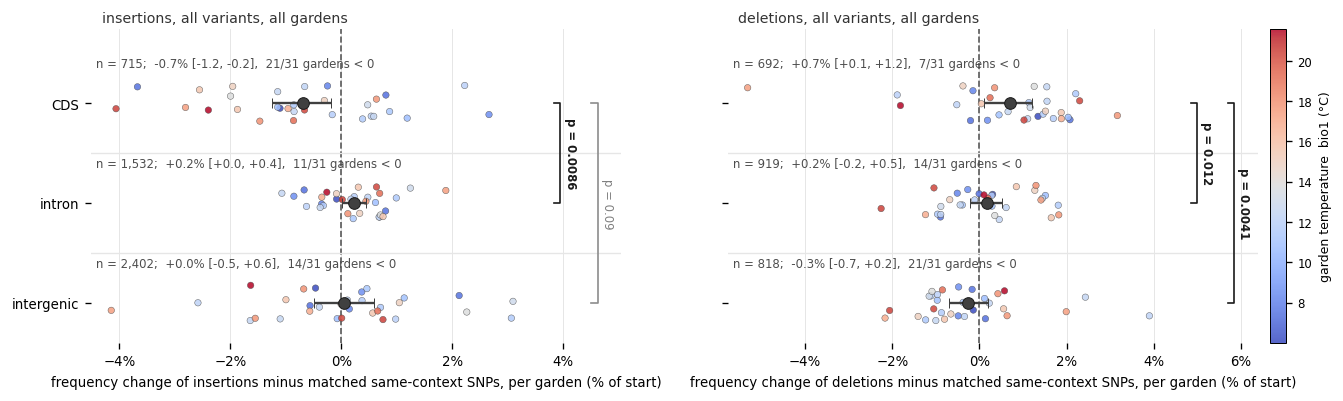

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0069  -0.0125  -0.0018           True             21               0.385
insertions     intron      1532  0.0022   0.0001   0.0045           True             11               0.496
insertions intergenic      2402  0.0005  -0.0049   0.0058          False             14               0.894
 deletions        CDS       692  0.0071   0.0011   0.0120           True              7               0.107
 deletions     intron       919  0.0016  -0.0022   0.0053          False             14               0.667
 deletions intergenic       818 -0.0027  -0.0070   0.0020          False             21               0.471

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [4]:

T,_=lead_figure(stat_freq,ALLV,"all variants, all gardens",XF,True,"supp_fig2c_summary_pooled.png",tag="1a frequency, all")
show(T)


### 1b. Frequency change — MAF ≥ 5%

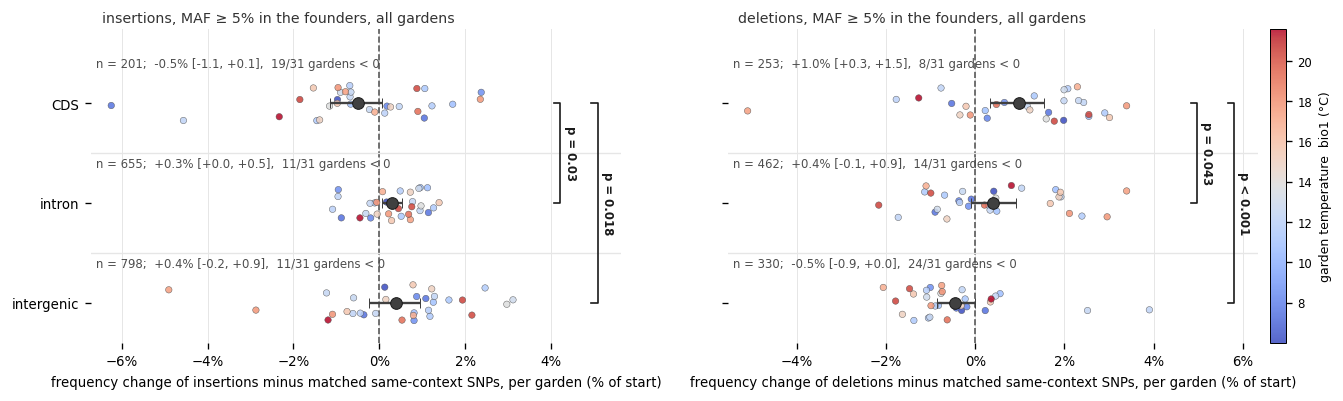

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       201 -0.0050  -0.0114   0.0006          False             19               0.513
insertions     intron       655  0.0030   0.0005   0.0054           True             11               0.381
insertions intergenic       798  0.0039  -0.0024   0.0094          False             11               0.330
 deletions        CDS       253  0.0099   0.0034   0.0154           True              8               0.028
 deletions     intron       462  0.0041  -0.0009   0.0090          False             14               0.291
 deletions intergenic       330 -0.0045  -0.0085   0.0000          False             24               0.286

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [5]:

T,_=lead_figure(stat_freq,COMMON,"MAF ≥ 5% in the founders, all gardens",XF,True,"main_fig2_lead_frequency_maf5.png",tag="1b frequency, MAF>=5%")
show(T)


### 1c. Frequency change, precision-weighted — all variants (top) and MAF ≥ 5% (bottom)

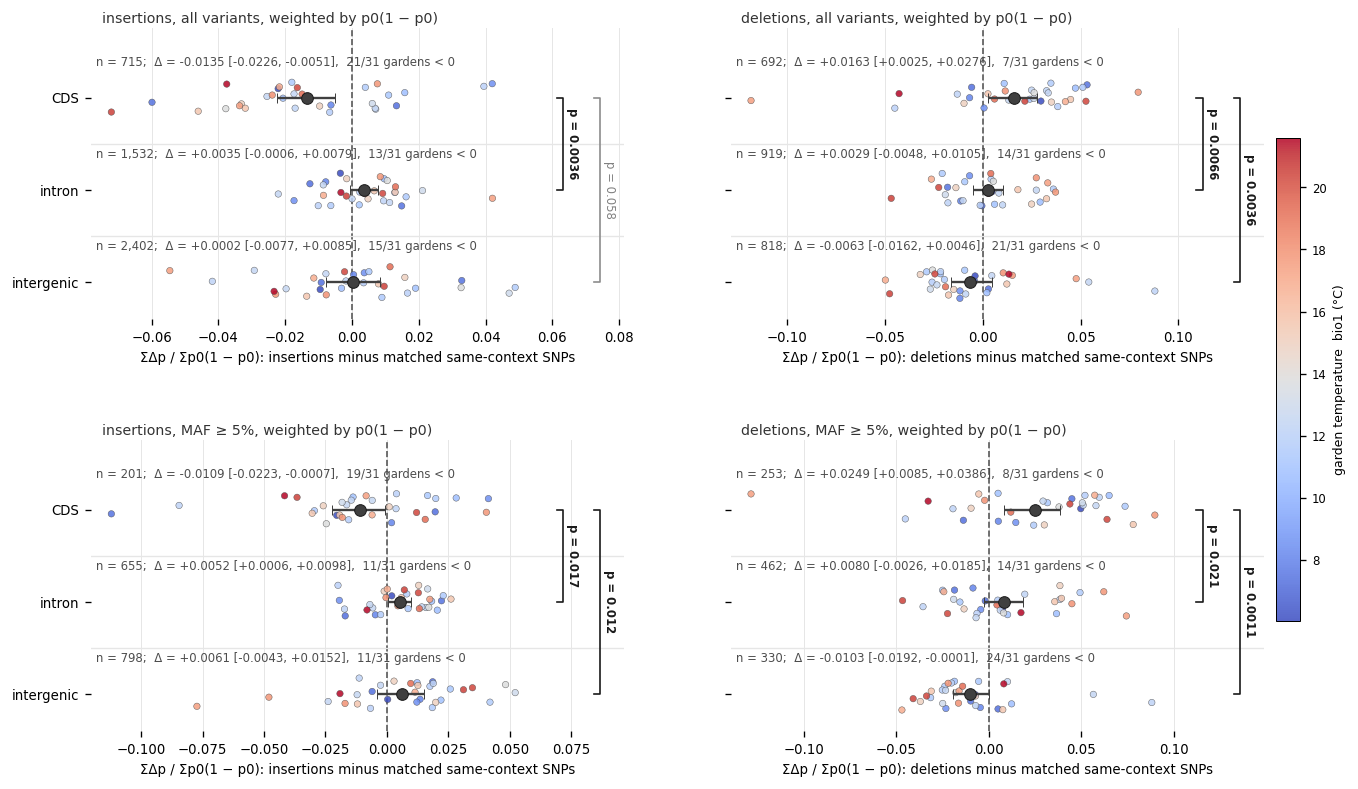

all variants:
      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0135  -0.0226  -0.0051           True             21               0.285
insertions     intron      1532  0.0035  -0.0006   0.0079          False             13               0.564
insertions intergenic      2402  0.0002  -0.0077   0.0085          False             15               0.969
 deletions        CDS       692  0.0163   0.0025   0.0276           True              7               0.124
 deletions     intron       919  0.0029  -0.0048   0.0105          False             14               0.702
 deletions intergenic       818 -0.0063  -0.0162   0.0046          False             21               0.454

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_

  all      insertions intergenic  r = 0.994   1c/1a =  0.38   Σp0(1−p0)/Σp0 = 0.64
  all      deletions  CDS         r = 0.998   1c/1a =  2.29   Σp0(1−p0)/Σp0 = 0.40
  all      deletions  intron      r = 0.998   1c/1a =  1.78   Σp0(1−p0)/Σp0 = 0.50
  all      deletions  intergenic  r = 1.000   1c/1a =  2.32   Σp0(1−p0)/Σp0 = 0.44


  MAF>=5%  insertions CDS         r = 0.998   1c/1a =  2.17   Σp0(1−p0)/Σp0 = 0.54
  MAF>=5%  insertions intron      r = 0.996   1c/1a =  1.76   Σp0(1−p0)/Σp0 = 0.52
  MAF>=5%  insertions intergenic  r = 0.999   1c/1a =  1.55   Σp0(1−p0)/Σp0 = 0.58
  MAF>=5%  deletions  CDS         r = 1.000   1c/1a =  2.51   Σp0(1−p0)/Σp0 = 0.38
  MAF>=5%  deletions  intron      r = 0.999   1c/1a =  1.97   Σp0(1−p0)/Σp0 = 0.48
  MAF>=5%  deletions  intergenic  r = 1.000   1c/1a =  2.28   Σp0(1−p0)/Σp0 = 0.44


In [6]:

XW="ΣΔp / Σp0(1 − p0): {kind} minus matched same-context SNPs"
fig,ax=plt.subplots(2,2,figsize=(13,7.6),sharey=True,gridspec_kw=dict(hspace=0.42))
T1,sc_=lead_figure(stat_freqw,ALLV,"all variants, weighted by p0(1 − p0)",XW,False,"",axes=ax[0],tag="1c weighted frequency, all",sym="Δ")
T2,sc_=lead_figure(stat_freqw,COMMON,"MAF ≥ 5%, weighted by p0(1 − p0)",XW,False,"",axes=ax[1],tag="1c weighted frequency, MAF>=5%",sym="Δ")
cb=fig.colorbar(sc_,ax=ax,pad=0.01,fraction=0.02); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.savefig(f"{G}/plots/main_fig2_lead_frequency_weighted.png",dpi=200,bbox_inches="tight"); plt.show()
show(T1,"all variants"); show(T2,"MAF >= 5%")
# how 1c relates to 1a/1b: same numerator (summed frequency change), different denominator
print("\n1c against 1a / 1b, garden by garden (Pearson r over the 31 gardens; ratio of the means; share of the class's summed p0 that is p0(1-p0)):")
for lab,flt in (("all",ALLV),("MAF>=5%",COMMON)):
    for k in ("ins","del"):
        for ctx in SUMC:
            ci=CTX.index(ctx); ms=(KD==k)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt; a_=load_diff(ms,mn); si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; b_=_wf(im,np.ones(im.size))-_wf(si,w)
            print(f"  {lab:<8} {KL[k]:<10} {ctx:<11} r = {np.corrcoef(a_,b_)[0,1]:.3f}   1c/1a = {b_.mean()/a_.mean():5.2f}   Σp0(1−p0)/Σp0 = {W0[im].sum()/P0[im].sum():.2f}")


### 2a. Selection coefficient — all variants

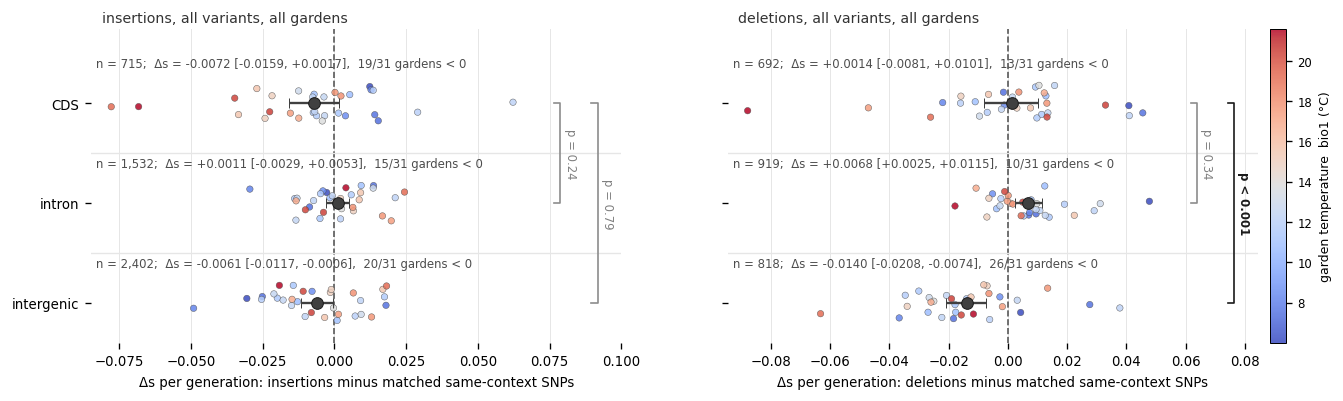

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0072  -0.0159   0.0017          False             19               0.349
insertions     intron      1532  0.0011  -0.0029   0.0053          False             15               0.783
insertions intergenic      2402 -0.0061  -0.0117  -0.0006           True             20               0.072
 deletions        CDS       692  0.0014  -0.0081   0.0101          False             13               0.803
 deletions     intron       919  0.0068   0.0025   0.0115           True             10               0.217
 deletions intergenic       818 -0.0140  -0.0208  -0.0074           True             26               0.011

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [7]:

T,_=lead_figure(stat_s,ALLV,"all variants, all gardens",XS,False,"main_fig2_lead_selection_coefficient.png",tag="2a s, all")
show(T)


### 2b. Selection coefficient — MAF ≥ 5%

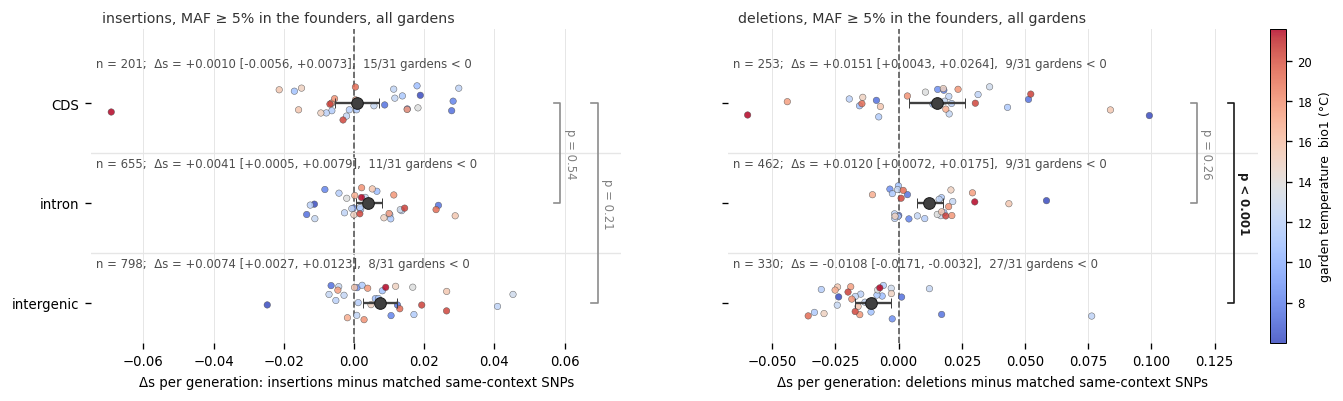

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       201  0.0010  -0.0056   0.0073          False             15               0.903
insertions     intron       655  0.0041   0.0005   0.0079           True             11               0.303
insertions intergenic       798  0.0074   0.0027   0.0123           True              8               0.063
 deletions        CDS       253  0.0151   0.0043   0.0264           True              9               0.038
 deletions     intron       462  0.0120   0.0072   0.0175           True              9               0.014
 deletions intergenic       330 -0.0108  -0.0171  -0.0032           True             27               0.059

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [8]:

T,_=lead_figure(stat_s,COMMON,"MAF ≥ 5% in the founders, all gardens",XS,False,"main_fig2_lead_selection_coefficient_maf5.png",tag="2b s, MAF>=5%")
show(T)


### 2c. Selection coefficient, precision-weighted — all variants (top) and MAF ≥ 5% (bottom)

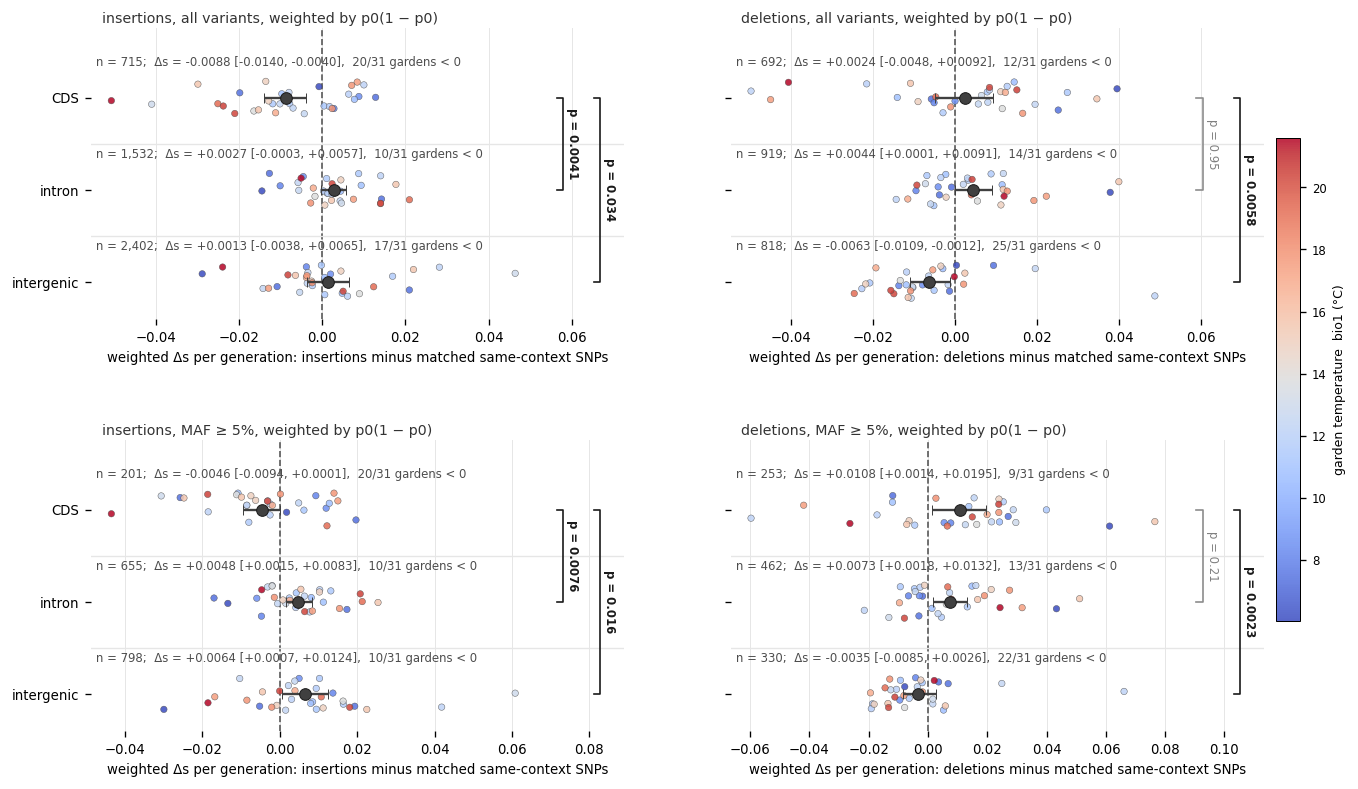

all variants:
      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0088  -0.0140  -0.0040           True             20               0.178
insertions     intron      1532  0.0027  -0.0003   0.0057          False             10               0.375
insertions intergenic      2402  0.0013  -0.0038   0.0065          False             17               0.619
 deletions        CDS       692  0.0024  -0.0048   0.0092          False             12               0.626
 deletions     intron       919  0.0044   0.0001   0.0091           True             14               0.265
 deletions intergenic       818 -0.0063  -0.0109  -0.0012           True             25               0.132

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_

In [9]:

fig,ax=plt.subplots(2,2,figsize=(13,7.6),sharey=True,gridspec_kw=dict(hspace=0.42))
T1,sc_=lead_figure(stat_sw,ALLV,"all variants, weighted by p0(1 − p0)","weighted "+XS,False,"",axes=ax[0],tag="2c weighted s, all")
T2,sc_=lead_figure(stat_sw,COMMON,"MAF ≥ 5%, weighted by p0(1 − p0)","weighted "+XS,False,"",axes=ax[1],tag="2c weighted s, MAF>=5%")
cb=fig.colorbar(sc_,ax=ax,pad=0.01,fraction=0.02); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.savefig(f"{G}/plots/main_fig2_lead_selection_coefficient_weighted.png",dpi=200,bbox_inches="tight"); plt.show()
show(T1,"all variants"); show(T2,"MAF >= 5%")


### Summary — coding insertions and coding deletions across the six versions

In [10]:

S_=pd.concat(SUMMARY); S_=S_[S_.context=="CDS"].copy()
S_["estimate [95% CI]"]=[(f"{100*m:+.1f}% [{100*l:+.1f}, {100*h:+.1f}]" if f[:2] in ("1a","1b") else f"{m:+.4f} [{l:+.4f}, {h:+.4f}]") for f,m,l,h in zip(S_.figure,S_["mean"],S_.boot_lo,S_.boot_hi)]
for k in ("insertions","deletions"):
    print(f"CDS {k} vs matched CDS SNPs"); print(S_[S_.kind==k][["figure","n_events","estimate [95% CI]","ci_excludes_0","gardens_below","matched_snp_null_p"]].to_string(index=False)); print()
C_=pd.concat(CONTRASTS); C_["difference [95% CI]"]=[(f"{100*m:+.1f}% [{100*l:+.1f}, {100*h:+.1f}]" if f[:2] in ("1a","1b") else f"{m:+.4f} [{l:+.4f}, {h:+.4f}]") for f,m,l,h in zip(C_.figure,C_.mean_diff,C_.boot_lo,C_.boot_hi)]
for k in ("insertions","deletions"):
    for c in ("CDS - intron","CDS - intergenic"):
        print(f"{k}: {c}"); print(C_[(C_.kind==k)&(C_.contrast==c)][["figure","difference [95% CI]","gardens_below","wilcoxon_p","significant","matched_snp_null_p"]].to_string(index=False)); print()


CDS insertions vs matched CDS SNPs
                        figure  n_events          estimate [95% CI]  ci_excludes_0  gardens_below  matched_snp_null_p
             1a frequency, all       715         -0.7% [-1.2, -0.2]           True             21               0.385
         1b frequency, MAF>=5%       201         -0.5% [-1.1, +0.1]          False             19               0.513
    1c weighted frequency, all       715 -0.0135 [-0.0226, -0.0051]           True             21               0.285
1c weighted frequency, MAF>=5%       201 -0.0109 [-0.0223, -0.0007]           True             19               0.434
                     2a s, all       715 -0.0072 [-0.0159, +0.0017]          False             19               0.349
                 2b s, MAF>=5%       201 +0.0010 [-0.0056, +0.0073]          False             15               0.903
            2c weighted s, all       715 -0.0088 [-0.0140, -0.0040]           True             20               0.178
        2c weighted s

### The same result as a site-frequency spectrum — seed mix → final generation

The lead statistic above is one number per garden (the class's summed frequency change against matched
SNPs). Here the same data are shown as a spectrum: where the frequency distribution of CDS insertions
moves between the seed mix and the last sampled generation, against the matched SNPs' spectrum over the
same interval.

**Tracked allele and folding.** Per variant the tracked allele is the one below 50% in the seed mix (the
*minor-at-founding* allele), and both timepoints are that same allele's frequency — the convention of
`_compute_sfs_shift_by_site.py`: no ancestral polarity is assumed (the insertion/deletion polarity caveat
does not enter) and nothing is reflected off 0.5 when it crosses. Founding frequencies are in [0, 0.5] by
construction; 0.14% of final-generation values exceed 0.5. Frequencies are kMate's pool frequencies
(`garden_af_event.npz`): column 0 = seed mix (mean of the 8 runs), columns 1–31 = each garden at its last
sampled generation (mean over the garden's plots).

**Comparison set.** The same matched SNPs the lead figure uses — same context, same carrier count, same
carrier-origin-climate quintile — entered as ECDF weights, so the SNP set's composition equals the
insertions'. The matching is close enough that the two seed-mix spectra coincide: mean tracked founding
frequency 0.0571 (insertions) vs 0.0570 (matched SNPs), share below 1% 0.194 vs 0.198.

**(a)** Both spectra at both timepoints. **(b)** The same thing as a residual — cumulative share at the
final generation minus at the seed mix, per class. The shared spike near 1% is drift plus pool sampling:
matched SNPs deplete nearly as much as insertions, so most of the visible leftward shift of the spectrum
is *not* selection. The selection signal is only the separation between the two curves. **(c)** That
separation decomposed by direction and founding frequency: per garden, the share of CDS insertions whose
tracked allele dropped to less than half its founding frequency, minus the same (weighted) share among
matched SNPs, and the mirror statistic for a rise to more than 1.5×. Purifying selection predicts excess
drops with no excess rises; symmetric estimation noise predicts excess in both. **(d)** Per context,
restricted to variants starting at ≥ 5% (where a relative-change statistic is least noise-dominated):
per garden, the insertions' mean relative change of the tracked allele minus the matched SNPs' weighted
mean, averaged over the 31 gardens.

*Statistics.* Every interval is a 95% percentile bootstrap over the 31 gardens (2,000 resamples), as in
the lead figure; gardens share one founder pool, so garden counts are descriptive. The printed tables
repeat each estimate with the SNPs additionally re-weighted to the insertions' founding-frequency deciles,
to rule out a p₀ mismatch inside a bin — the matching is on carrier count, not on p₀ itself.

**What it shows and what it does not.** The asymmetry in (c) is confined to the 1–2% founding-frequency
bin and is flat in the other three: a one-bin effect, not a gradient across the spectrum, and unexplained.
In (d) the ordering CDS > intron > TE, promoter, UTR > intergenic is the functional gradient purifying
selection predicts, but the CDS interval rests on 202 events and barely excludes zero, and nothing here is
corrected for the six contexts tested. A crude absolute-threshold statistic (share below 1%) does *not*
reproduce the CDS specificity — introns score higher on it — so the direction decomposition in (c) is
doing the work, not the spectrum shift on its own.

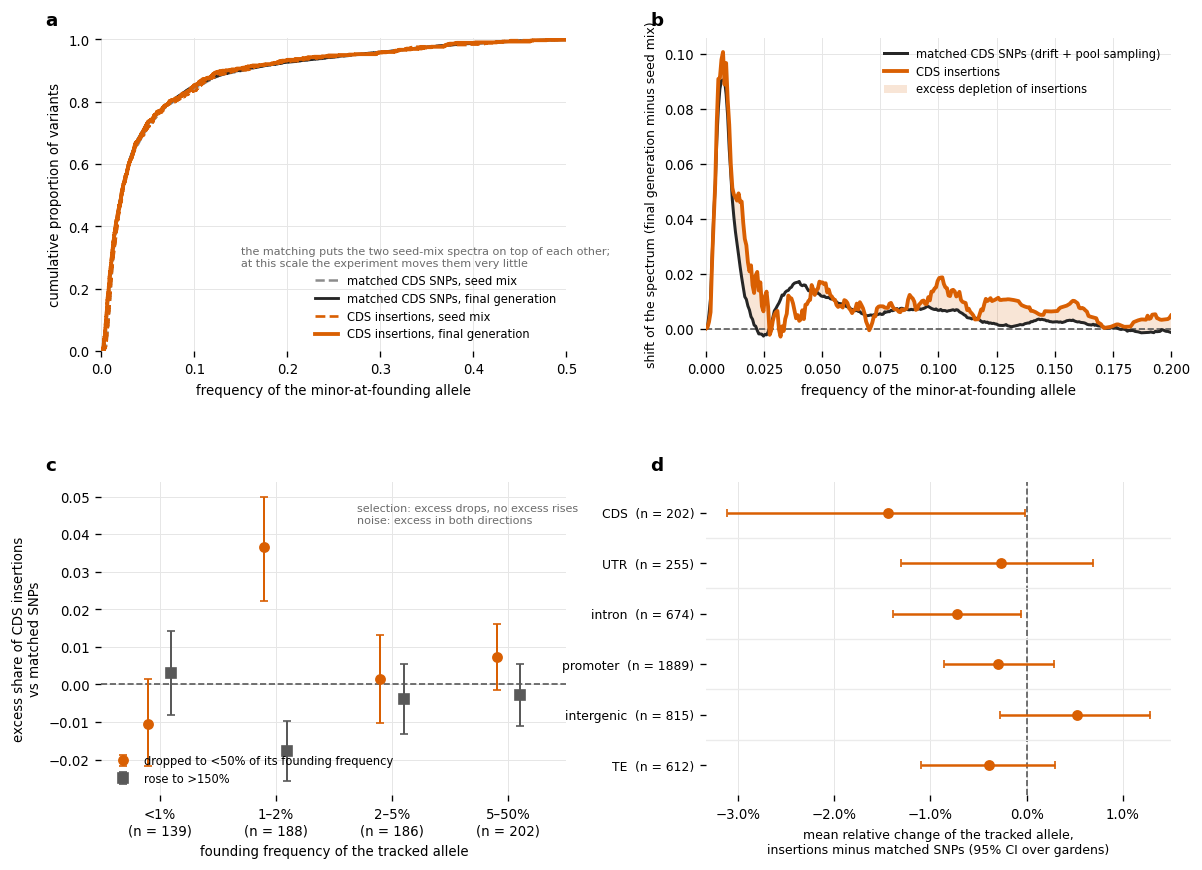

(a, b) share of the class below a frequency threshold, seed mix vs final generation:
 threshold  ins_seed  ins_final  ins_change  snp_seed  snp_final  snp_change  excess
      0.01    0.1944     0.2699      0.0755    0.1978     0.2637      0.0660  0.0095
      0.02    0.4573     0.4727      0.0154    0.4796     0.4830      0.0034  0.0120
      0.05    0.7175     0.7329      0.0154    0.7164     0.7281      0.0116  0.0038

(c) excess share of CDS insertions vs matched SNPs, by direction and founding frequency
    (excess_p0matched: SNPs additionally re-weighted to the insertions' p0 deciles):
direction   bin  n_ins  excess      lo      hi  gardens_pos  excess_p0matched   lo_p0   hi_p0
     drop   <1%    139 -0.0105 -0.0216  0.0015           11           -0.0072 -0.0179  0.0043
     drop  1–2%    188  0.0366  0.0222  0.0500           26            0.0375  0.0234  0.0508
     drop  2–5%    186  0.0014 -0.0102  0.0132           16           -0.0006 -0.0120  0.0111
     drop 5–50%    202  0

In [11]:

def tracked(idx):
    # the allele below 50% in the seed mix, at both timepoints: no polarity assumed, no reflection at 0.5
    p0=PV[idx,0]; pg=PV[idx,1:]; flip=p0>0.5
    return np.where(flip,1-p0,p0), np.where(flip[:,None],1-pg,pg)
def wecdf(a,v,w,**k):
    o=np.argsort(v); v=v[o]; c=np.cumsum(w[o])/w.sum(); a.step(np.r_[0,v],np.r_[0,c],where="post",**k)
def wecdf_at(v,w,x):
    o=np.argsort(v); vs=v[o]; c=np.cumsum(w[o])/w.sum(); return np.interp(x,vs,c,left=0,right=1)
def wshare(v,w,lo=None,hi=None):
    m=np.isfinite(v)
    if lo is not None: m&=v<lo
    if hi is not None: m&=v>hi
    return w[m].sum()/w.sum()
def p0_reweight(pi,ps,ws,nq=10):
    # founding-frequency matching on top of the carrier-count matching: SNPs re-weighted to the events' p0 deciles
    qs=np.quantile(pi,np.linspace(0,1,nq+1)); qs[0]=-np.inf; qs[-1]=np.inf
    bi=np.digitize(pi,qs[1:-1]); bs=np.digitize(ps,qs[1:-1]); w2=np.zeros(ps.size)
    for d in range(nq):
        tgt=(bi==d).sum(); pool=bs==d
        if tgt and ws[pool].sum()>0: w2[pool]+=ws[pool]*tgt/ws[pool].sum()
    return w2
ci0=CTX.index("CDS"); ms=(KD=="ins")&(CX==ci0); mn=(KD=="snp")&(CX==ci0)
si,w,_=matched_snps(ms,mn); p0i,pgi=tracked(np.where(ms)[0]); p0s,pgs=tracked(si)
wi=np.ones(p0i.size); pfi=pgi.mean(1); pfs=pgs.mean(1)
fig=plt.figure(figsize=(11.5,8.2)); gs_=fig.add_gridspec(2,2,wspace=0.30,hspace=0.42)
# (a) both spectra, seed mix and final generation
a=fig.add_subplot(gs_[0,0]); style(a); panel(a,"a")
for v,ww,col,ls,lw,lab in ((p0s,w,"0.55","--",1.5,"matched CDS SNPs, seed mix"),(pfs,w,"0.15","-",1.7,"matched CDS SNPs, final generation"),
                           (p0i,wi,KC["ins"],"--",1.6,"CDS insertions, seed mix"),(pfi,wi,KC["ins"],"-",2.3,"CDS insertions, final generation")):
    wecdf(a,v,ww,color=col,ls=ls,lw=lw,label=lab)
a.set_xlim(0,0.5); a.set_ylim(0,1.005); a.set_xlabel("frequency of the minor-at-founding allele")
a.set_ylabel("cumulative proportion of variants"); a.legend(frameon=False,fontsize=6.9,loc="lower right")
a.annotate("the matching puts the two seed-mix spectra on top of each other;\nat this scale the experiment moves them very little",
           xy=(0.30,0.27),xycoords="axes fraction",fontsize=6.7,color="0.42")
# (b) the same as a residual: cumulative share at the final generation minus at the seed mix
a=fig.add_subplot(gs_[0,1]); style(a); panel(a,"b"); a.axhline(0,color="0.35",lw=1,ls="--")
xg=np.linspace(0,0.2,300); dS=wecdf_at(pfs,w,xg)-wecdf_at(p0s,w,xg); dI=wecdf_at(pfi,wi,xg)-wecdf_at(p0i,wi,xg)
a.plot(xg,dS,color="0.15",lw=1.8,label="matched CDS SNPs (drift + pool sampling)")
a.plot(xg,dI,color=KC["ins"],lw=2.3,label="CDS insertions")
a.fill_between(xg,dS,dI,where=dI>=dS,color=KC["ins"],alpha=0.16,lw=0,label="excess depletion of insertions")
a.set_xlim(0,0.2); a.set_xlabel("frequency of the minor-at-founding allele")
a.set_ylabel("shift of the spectrum (final generation minus seed mix)",fontsize=7.5)
a.legend(frameon=False,fontsize=6.9,loc="upper right")
# (c) the separation decomposed: direction x founding frequency
a=fig.add_subplot(gs_[1,0]); style(a); panel(a,"c"); a.axhline(0,color="0.35",lw=1,ls="--")
EDG=[0,0.01,0.02,0.05,0.5]; LBL=["<1%","1–2%","2–5%","5–50%"]; ri=pgi/p0i[:,None]; rs=pgs/p0s[:,None]; SFSB=[]
for sgn,col,mk,lab in (("drop",KC["ins"],"o","dropped to <50% of its founding frequency"),("rise","0.35","s","rose to >150%")):
    xs=[];ys=[];los=[];his=[]
    for b in range(len(EDG)-1):
        bmi=(p0i>=EDG[b])&(p0i<EDG[b+1]); bms=(p0s>=EDG[b])&(p0s<EDG[b+1])
        if bmi.sum()<20: continue
        w2=p0_reweight(p0i[bmi],p0s[bms],w[bms]); kw=dict(lo=0.5) if sgn=="drop" else dict(hi=1.5)
        d=np.array([wshare(ri[bmi,g],wi[bmi],**kw)-wshare(rs[bms,g],w[bms],**kw) for g in range(31)])
        dp=np.array([wshare(ri[bmi,g],wi[bmi],**kw)-wshare(rs[bms,g],w2,**kw) for g in range(31)])
        lo,hi=bci(d); lp,hp=bci(dp)
        xs.append(b+(-0.1 if sgn=="drop" else 0.1)); ys.append(d.mean()); los.append(d.mean()-lo); his.append(hi-d.mean())
        SFSB.append(dict(direction=sgn,bin=LBL[b],n_ins=int(bmi.sum()),excess=d.mean(),lo=lo,hi=hi,
                         gardens_pos=int((d>0).sum()),excess_p0matched=dp.mean(),lo_p0=lp,hi_p0=hp))
    a.errorbar(xs,ys,yerr=[los,his],fmt=mk,color=col,ms=5.5,capsize=2.5,lw=0,elinewidth=1.2,label=lab)
a.set_xticks(range(len(LBL))); a.set_xticklabels([f"{l}\n(n = {int(((p0i>=EDG[i])&(p0i<EDG[i+1])).sum())})" for i,l in enumerate(LBL)])
a.set_xlim(-0.5,len(LBL)-0.5); a.set_xlabel("founding frequency of the tracked allele")
a.set_ylabel("excess share of CDS insertions\nvs matched SNPs")
a.legend(frameon=False,fontsize=6.9,loc="lower left")
a.annotate("selection: excess drops, no excess rises\nnoise: excess in both directions",
           xy=(0.55,0.87),xycoords="axes fraction",fontsize=6.7,color="0.42")
# (d) per context, variants starting at >= 5%
a=fig.add_subplot(gs_[1,1]); style(a,axis="x"); panel(a,"d"); a.axvline(0,color="0.35",lw=1,ls="--")
order=["TE","intergenic","promoter","intron","UTR","CDS"]; FOLD0=np.minimum(PV[:,0],1-PV[:,0]); SFSC=[]; ylab=[]
for yi,ctx in enumerate(order):
    cc=CTX.index(ctx); m1=(KD=="ins")&(CX==cc)&(FOLD0>=0.05); m2=(KD=="snp")&(CX==cc)&(FOLD0>=0.05)
    s2,w2,_=matched_snps(m1,m2); q0i,qgi=tracked(np.where(m1)[0]); q0s,qgs=tracked(s2)
    w3=p0_reweight(q0i,q0s,w2)
    d=np.array([(qgi[:,g]/q0i-1).mean()-((qgs[:,g]/q0s-1)*w2).sum()/w2.sum() for g in range(31)])
    dp=np.array([(qgi[:,g]/q0i-1).mean()-((qgs[:,g]/q0s-1)*w3).sum()/w3.sum() for g in range(31)])
    lo,hi=bci(d); lp,hp=bci(dp)
    a.errorbar(d.mean(),yi,xerr=[[d.mean()-lo],[hi-d.mean()]],fmt="o",color=KC["ins"],ms=5.5,capsize=2.5,zorder=3)
    ylab.append(f"{ctx}  (n = {int(m1.sum())})")
    SFSC.append(dict(context=ctx,n_ins=int(m1.sum()),mean=d.mean(),lo=lo,hi=hi,gardens_neg=int((d<0).sum()),
                     mean_p0matched=dp.mean(),lo_p0=lp,hi_p0=hp))
    if yi<5: a.axhline(yi+0.5,color="0.92",lw=0.8)
a.set_yticks(range(6)); a.set_yticklabels(ylab,fontsize=7.4); a.set_ylim(-0.6,5.6)
a.set_xlabel("mean relative change of the tracked allele,\ninsertions minus matched SNPs (95% CI over gardens)",fontsize=7.5)
a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=1))
fig.savefig(f"{G}/plots/sfs_seedmix_vs_final.png",dpi=200,bbox_inches="tight")
fig.savefig(f"{G}/plots/sfs_seedmix_vs_final.pdf",bbox_inches="tight"); plt.show()
SFSA=[dict(threshold=t,ins_seed=wshare(p0i,wi,lo=t),ins_final=wshare(pfi,wi,lo=t),snp_seed=wshare(p0s,w,lo=t),snp_final=wshare(pfs,w,lo=t)) for t in (0.01,0.02,0.05)]
for r_ in SFSA: r_["ins_change"]=r_["ins_final"]-r_["ins_seed"]; r_["snp_change"]=r_["snp_final"]-r_["snp_seed"]; r_["excess"]=r_["ins_change"]-r_["snp_change"]
print("(a, b) share of the class below a frequency threshold, seed mix vs final generation:")
print(pd.DataFrame(SFSA)[["threshold","ins_seed","ins_final","ins_change","snp_seed","snp_final","snp_change","excess"]].round(4).to_string(index=False))
print("\n(c) excess share of CDS insertions vs matched SNPs, by direction and founding frequency")
print("    (excess_p0matched: SNPs additionally re-weighted to the insertions' p0 deciles):")
print(pd.DataFrame(SFSB).round(4).to_string(index=False))
print("\n(d) mean relative change of the tracked allele, insertions minus matched SNPs, founding frequency >= 5%:")
print(pd.DataFrame(SFSC).round(4).to_string(index=False))


#### One garden at a time

The spectra above use each event's frequency averaged over the 31 gardens, which suppresses
per-garden noise by roughly √31 but also averages away anything garden-specific. Here the same
spectra are drawn one garden at a time: **(a)** site 4 and **(b)** site 32, plus **(c)** site 24,
the coldest garden, as a contrast. **(d)** the per-garden statistic for all 31 gardens against
garden temperature.

**Read (a)–(c) with the matched-SNP curve, not the insertion curve.** Averaging over gardens is what
kept panel (a) of the previous figure nearly still; in a single garden the whole spectrum collapses
toward rare — the share of CDS insertions below 1% goes from 0.19 in the seed mix to 0.49 in site 4
and 0.52 in site 32. Almost none of that is selection: the matched SNPs move the same distance in the
same gardens (0.48 and 0.52 respectively). A single garden's spectrum is one noisy realisation — pool
sampling, drift in a small plot, and kMate estimation error all land on it — so the only interpretable
quantity remains the gap between the insertion and matched-SNP curves.

*Statistics.* Per garden there is no bootstrap over gardens to take, so the intervals here are a
bootstrap over **events** (2,000 resamples of the insertions, and of the weighted matched-SNP set);
the inference target is therefore "within this garden, do insertions differ from their matched SNPs?",
not "does this generalise across gardens". The statistic is the one from panel (d) of the previous
figure: the insertions' mean relative change of the tracked allele minus the matched SNPs' weighted
mean, restricted to variants starting at ≥ 5%.

**What the named sites do.** Site 4 is the most extreme garden in the whole panel (−17.6%, rank 1 of
31), but on 202 events in one garden the event-bootstrap interval is [−37.3, +3.7] and includes zero,
so on its own it is suggestive rather than conclusive. Site 32, despite also being a hot garden, is
unremarkable on this statistic (−0.5%, rank 17 of 31) — whatever makes it a strong-selection site does
not show up as excess purging of CDS insertions. The structure is in (d) rather than in any single
garden: the excess decline of insertions is stronger in warmer gardens, and is near zero or slightly
positive in the cold ones. That gradient is already part of this figure's established result — Figure 2c
reports the same slope on the load statistic (−0.0016/°C, p = 0.022) — and by the criterion stated
there, a slope on temperature is the signature of lineage sorting rather than of uniform purifying
selection, so it should not be read as strengthening the CDS-purging claim.

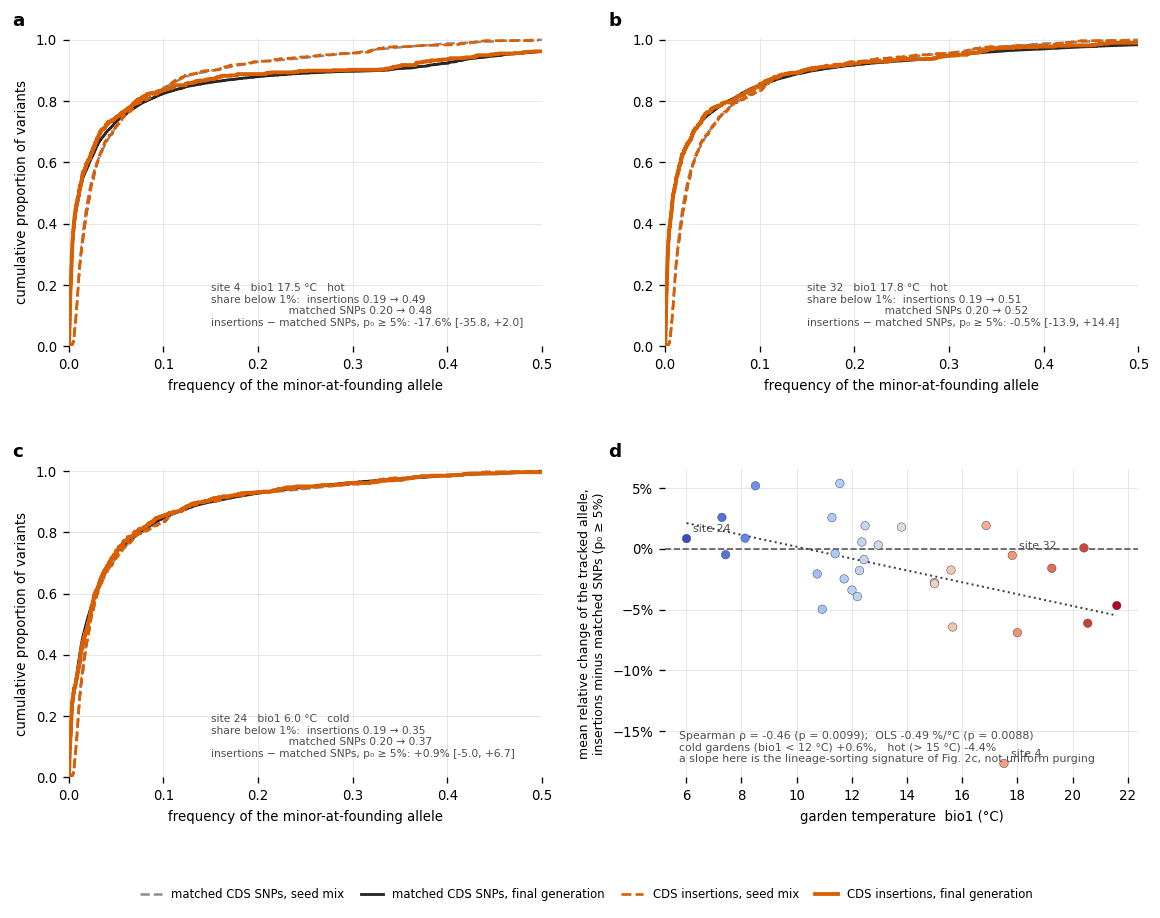

highlighted gardens (intervals are a bootstrap over EVENTS, 2,000 resamples, not over gardens):
 site    bio1 zone  ins_lt1_seed  ins_lt1_final  snp_lt1_seed  snp_lt1_final  relch_p0ge5  event_boot_lo  event_boot_hi
    4 17.5135  hot        0.1944         0.4867        0.1978         0.4771      -0.1764        -0.3580         0.0204
   32 17.8152  hot        0.1944         0.5147        0.1978         0.5197      -0.0053        -0.1391         0.1438
   24  6.0089 cold        0.1944         0.3524        0.1978         0.3693       0.0085        -0.0498         0.0672

all 31 gardens, sorted by temperature (rank 1 = strongest excess decline of insertions):
 site    bio1 zone  relch_p0ge5  relch_all  ins_lt1_final  snp_lt1_final  rank_relch
   24  6.0089 cold       0.0085    -0.0158         0.3524         0.3693          23
   23  7.2909 cold       0.0259     0.0099         0.2825         0.2742          29
   27  7.4251 cold      -0.0048     0.0331         0.5063         0.5131       

In [12]:

SITE=GS["sites"]; ZN_=GS["zone"].astype(str)
SEL=[4,32,24]                                          # sites 4 and 32, plus the coldest garden as a contrast
gidx={int(s):int(np.where(SITE==s)[0][0]) for s in SEL}
g5i=p0i>=0.05; g5s=p0s>=0.05
def relch(g):
    return (pgi[g5i,g]/p0i[g5i]-1).mean()-((pgs[g5s,g]/p0s[g5s]-1)*w[g5s]).sum()/w[g5s].sum()
rngG=np.random.default_rng(7)
def relch_boot(g,B=2000):
    out=np.empty(B)
    for t in range(B):
        a_=rngG.integers(0,p0i.size,p0i.size); b_=rngG.integers(0,p0s.size,p0s.size)
        ai=a_[p0i[a_]>=0.05]; bi=b_[p0s[b_]>=0.05]
        out[t]=(pgi[ai,g]/p0i[ai]-1).mean()-((pgs[bi,g]/p0s[bi]-1)*w[bi]).sum()/w[bi].sum()
    return np.percentile(out,[2.5,97.5])
fig=plt.figure(figsize=(11.5,8.0)); gs_=fig.add_gridspec(2,2,wspace=0.26,hspace=0.40); SFSG=[]
for k_,s_ in enumerate(SEL):
    g=gidx[s_]; a=fig.add_subplot(gs_[k_//2,k_%2]); style(a); panel(a,"abc"[k_])
    for v,ww,col,ls,lw,lab in ((p0s,w,"0.55","--",1.5,"matched CDS SNPs, seed mix"),(pgs[:,g],w,"0.15","-",1.7,"matched CDS SNPs, final generation"),
                               (p0i,wi,KC["ins"],"--",1.6,"CDS insertions, seed mix"),(pgi[:,g],wi,KC["ins"],"-",2.3,"CDS insertions, final generation")):
        wecdf(a,v,ww,color=col,ls=ls,lw=lw,label=lab)
    a.set_xlim(0,0.5); a.set_ylim(0,1.005); a.set_xlabel("frequency of the minor-at-founding allele")
    if k_%2==0: a.set_ylabel("cumulative proportion of variants")
    lo,hi=relch_boot(g); r5=relch(g)
    SFSG.append(dict(site=s_,bio1=BIO[g],zone=ZN_[g],ins_lt1_seed=wshare(p0i,wi,lo=0.01),ins_lt1_final=wshare(pgi[:,g],wi,lo=0.01),
                     snp_lt1_seed=wshare(p0s,w,lo=0.01),snp_lt1_final=wshare(pgs[:,g],w,lo=0.01),relch_p0ge5=r5,event_boot_lo=lo,event_boot_hi=hi))
    a.annotate(f"site {s_}   bio1 {BIO[g]:.1f} °C   {ZN_[g]}\nshare below 1%:  insertions {wshare(p0i,wi,lo=0.01):.2f} → {wshare(pgi[:,g],wi,lo=0.01):.2f}\n"
               f"                       matched SNPs {wshare(p0s,w,lo=0.01):.2f} → {wshare(pgs[:,g],w,lo=0.01):.2f}\n"
               f"insertions − matched SNPs, p₀ ≥ 5%: {100*r5:+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}]",
               xy=(0.30,0.06),xycoords="axes fraction",ha="left",va="bottom",fontsize=6.4,color="0.3")
    if k_==0: h_,l_=a.get_legend_handles_labels()
# (d) all 31 gardens against garden temperature
a=fig.add_subplot(gs_[1,1]); style(a); panel(a,"d"); a.axhline(0,color="0.35",lw=1,ls="--")
RC=np.array([relch(g) for g in range(31)])
a.scatter(BIO,RC,c=BIO,cmap="coolwarm",vmin=BIO.min(),vmax=BIO.max(),s=26,linewidth=0.3,edgecolor="0.3",zorder=3)
lr=stats.linregress(BIO,RC); xx=np.linspace(BIO.min(),BIO.max(),50); a.plot(xx,lr.intercept+lr.slope*xx,color="0.25",lw=1.2,ls=":")
rho,prho=stats.spearmanr(BIO,RC)
for s_ in SEL:
    g=gidx[s_]; a.annotate(f"site {s_}",xy=(BIO[g],RC[g]),xytext=(4,4),textcoords="offset points",fontsize=6.6,color="0.3")
a.set_xlabel("garden temperature  bio1 (°C)")
a.set_ylabel("mean relative change of the tracked allele,\ninsertions minus matched SNPs (p₀ ≥ 5%)",fontsize=7.5)
a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
a.annotate(f"Spearman ρ = {rho:+.2f} (p = {prho:.2g});  OLS {100*lr.slope:+.2f} %/°C (p = {lr.pvalue:.2g})\n"
           f"cold gardens (bio1 < 12 °C) {100*RC[BIO<12].mean():+.1f}%,   hot (> 15 °C) {100*RC[BIO>15].mean():+.1f}%\n"
           f"a slope here is the lineage-sorting signature of Fig. 2c, not uniform purging",
           xy=(0.03,0.05),xycoords="axes fraction",fontsize=6.6,color="0.3")
fig.legend(h_,l_,frameon=False,fontsize=7,loc="lower center",bbox_to_anchor=(0.5,-0.03),ncol=4,columnspacing=1.4,handlelength=1.9)
fig.savefig(f"{G}/plots/sfs_per_garden.png",dpi=200,bbox_inches="tight")
fig.savefig(f"{G}/plots/sfs_per_garden.pdf",bbox_inches="tight"); plt.show()
print("highlighted gardens (intervals are a bootstrap over EVENTS, 2,000 resamples, not over gardens):")
print(pd.DataFrame(SFSG).round(4).to_string(index=False))
ALLG=pd.DataFrame(dict(site=SITE,bio1=BIO,zone=ZN_,relch_p0ge5=RC,
                       relch_all=[(pgi[:,g]/p0i-1).mean()-((pgs[:,g]/p0s-1)*w).sum()/w.sum() for g in range(31)],
                       ins_lt1_final=[wshare(pgi[:,g],wi,lo=0.01) for g in range(31)],
                       snp_lt1_final=[wshare(pgs[:,g],w,lo=0.01) for g in range(31)]))
ALLG["rank_relch"]=ALLG.relch_p0ge5.rank().astype(int)
print("\nall 31 gardens, sorted by temperature (rank 1 = strongest excess decline of insertions):")
print(ALLG.round(4).to_string(index=False))
r2,p2=stats.spearmanr(ALLG.bio1,ALLG.relch_all)
print(f"\nclimate gradient: p0 >= 5% statistic Spearman rho = {rho:+.3f} (p = {prho:.3g});  all-event statistic rho = {r2:+.3f} (p = {p2:.3g})")
print("the all-event version is a mean of ratios, dominated by the rarest events; the p0 >= 5% version is the one plotted.")
print(f"for comparison, Figure 2c's load statistic on the same gardens: slope {stats.linregress(BIO,load_diff((KD=='ins')&(CX==ci0),(KD=='snp')&(CX==ci0))).slope:+.4f}/°C")


## Figure 2 — GrENE-Net: is the selection still acting?

kMate estimates, for every pooled sample, the founder (ecotype) composition *h* from the k-mers and
derives each variant's allele frequency from it; within GrENE-Net a variant therefore moves with the
founders that carry it. The test of selection on SVs is at the founder level (a–b); (c–d) show the
same experiment at the level of the variants themselves, using kMate's stored per-pool allele
frequencies (`_sv_garden_af.py`): the founding frequency is the mean of the 8 seed-mix runs, and a
garden's frequency is the mean over its plots of each plot's frequency at its last sampled generation
(352 pools, 31 gardens). An SV event's frequency is the sum of its alleles' frequencies (capped at 1).

**(a)** Founder burden. For each founder *f*, mean log-fitness over the 31 gardens,
*y*<sub>*f*</sub> = mean<sub>*s*</sub> log[(*H*<sub>0,*f*</sub> + Δ*H*<sub>*s*,*f*</sub> + 10⁻⁵) /
(*H*<sub>0,*f*</sub> + 10⁻⁵)], with *H*<sub>0</sub> the founding ecotype frequency (mean of 8 seed-mix
estimates) and *H*<sub>0</sub> + Δ*H*<sub>*s*</sub> the last-generation ecotype frequency in garden *s*
(plots equally weighted). The mixed model, fit by REML, is

> *y* = β₀ + β₁·z(*r*<sub>context</sub>) + β₂·z(*r*<sub>intergenic</sub>) + β₃·z(call rate, SVs) +
> β₄·z(call rate, SNPs) + β₅·[sequencing route] + *u* + ε,  *u* ~ N(0, σ²<sub>g</sub>**K**),
> ε ~ N(0, σ²<sub>e</sub>**I**)

where *r*<sub>context</sub> = (variants of the class carried) / (variants of the class called) for
the founder, *r*<sub>intergenic</sub> the same for intergenic variants of the same kind and origin
(the within-class baseline), z(·) standardises to unit SD, and **K** is the SNP kinship matrix
(standardised GRM from a 2% SNP draw). Shown: β₁ ± 1.96 SE (Wald), shared variants (carried by both
cold- and warm-origin founders), per context and variant kind. **(b)** The same relation in the raw
data: founder mean log-fitness against the standardised shared-CDS-insertion burden, one point per
founder coloured by origin temperature, with the OLS line and 95% band (the mixed model in (a) adds
the covariates and the kinship term). **(c)** Frequency change against matched SNPs. For each CDS insertion, its allele-frequency change from
the seed mix to the garden minus the mean change of its matched SNPs: the CDS SNPs carried by the same
number of founders and by founders of the same origin-climate quintile, so SNPs that started at the same
frequency on the same kind of founder background. The 715 differences are averaged and expressed relative
to the insertions' starting frequency. One
dot per garden against the garden's temperature: purifying selection shows as an offset below zero
across the whole range, lineage sorting would show as a slope. Solid line and band = mean ± 95% CI over
gardens; dotted = OLS on temperature; deletions alongside. The p-value is **empirical**:
gardens share one founder pool and are not independent, so the observed mean is compared with 1,000
random sets of CDS SNPs, one per insertion drawn from its matched SNPs
(one-sided for insertions, two-sided for deletions). **(d)** Climate of origin × garden climate. For variants private
to cold-origin or to warm-origin founders, the log load change per garden, log[*L*<sub>garden</sub>/*L*<sub>0</sub>],
regressed on garden temperature (OLS over 31 gardens; slope ± 1.96 SE), for insertions, deletions,
short indels and SNPs alike. A negative slope = the class loses more in warmer gardens.

/tmp/ipykernel_1230893/1649503904.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); fig.savefig(f"{G}/plots/main_fig2.png",dpi=200); fig.savefig(f"{G}/plots/main_fig2.pdf"); plt.show()


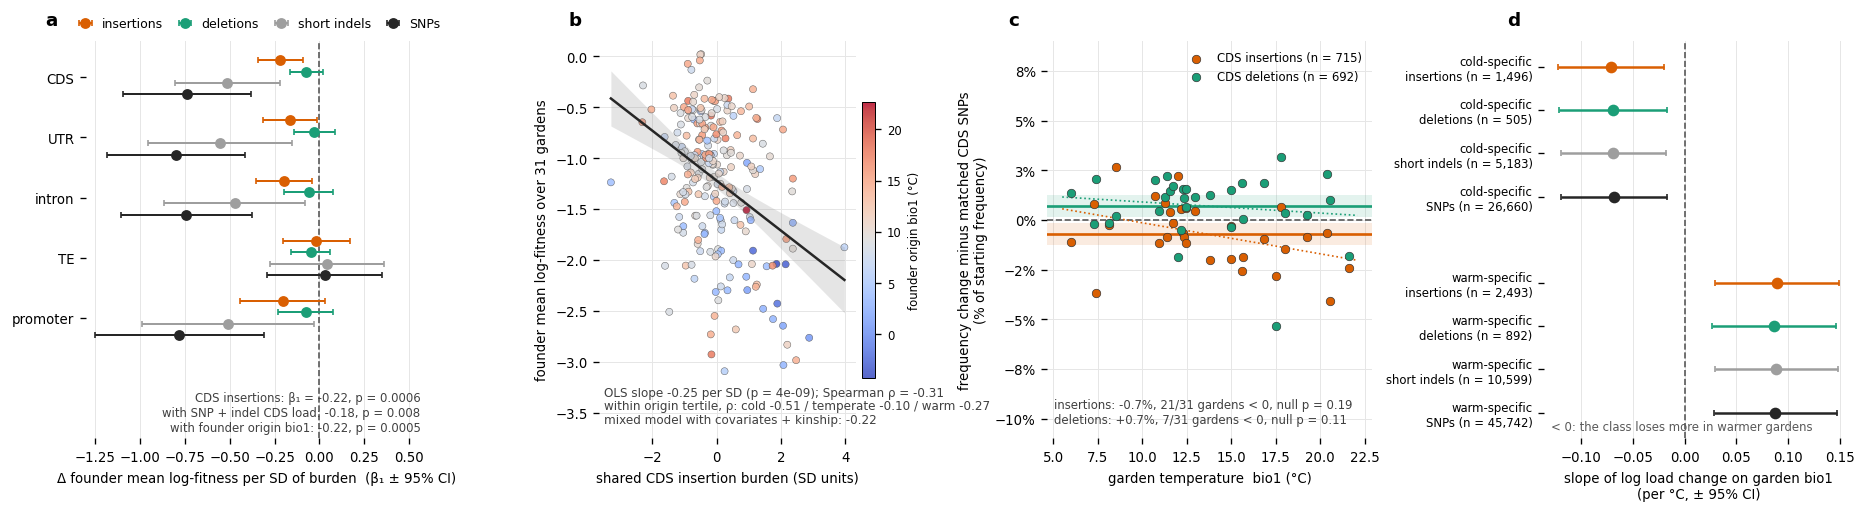

Figure 2a  β₁ per SD, shared variants (p):
context                   CDS              UTR           intron            TE        promoter
kind                                                                                         
deletions        -0.07 (0.12)     -0.03 (0.61)      -0.06 (0.4)  -0.05 (0.37)    -0.08 (0.33)
short indels  -0.51 (0.00059)   -0.55 (0.0069)    -0.47 (0.018)   +0.04 (0.8)   -0.51 (0.038)
insertions    -0.22 (0.00059)    -0.16 (0.033)    -0.20 (0.013)  -0.02 (0.86)   -0.21 (0.087)
SNPs          -0.74 (4.7e-05)  -0.80 (4.3e-05)  -0.74 (7.2e-05)  +0.03 (0.86)  -0.78 (0.0011)

Figure 2c  all CDS insertions: mean -0.0069, 21/31 below 0; slope on garden bio1 -0.0016/°C (p = 0.022)

Figure 2c  all CDS deletions: mean +0.0071, 7/31 below 0; slope on garden bio1 -0.0006/°C (p = 0.44)

Figure 2d  log load change vs garden bio1, OLS over 31 gardens:
       origin          cls     n  slope_per_C      se       p  mean_log_change
cold-specific   insertions  1496     -0.07

In [13]:

R=pd.read_csv(f"{G}/sv_burden_lmm_event.csv"); J=pd.read_csv(f"{G}/sv_burden_lmm_joint_event.csv")
fig,ax=plt.subplots(1,4,figsize=(19,4.3),gridspec_kw=dict(width_ratios=[1.05,0.85,1.0,0.95],wspace=0.55))
# (a) forest
a=ax[0]; style(a,axis="x"); panel(a,"a"); a.axvline(0,color="0.35",lw=1,ls="--"); C5=["CDS","UTR","intron","TE","promoter"]
for j,k in enumerate(("ins","del","indel","snp")):
    d=R[(R.freq=="all")&(R.kind==k)&(R.origin=="shared")].set_index("context").reindex(C5); y=np.arange(5)+(j-1.5)*0.19
    a.errorbar(d.beta,y,xerr=1.96*d.se,fmt="o",ms=5.5,color=KC[k],ecolor=KC[k],elinewidth=1.2,capsize=2,label=KL[k])
a.set_yticks(range(5)); a.set_yticklabels(C5); a.set_ylim(6.0,-0.6); a.set_xlim(-1.3,0.6)
a.legend(frameon=False,fontsize=7.5,loc="lower center",bbox_to_anchor=(0.5,1.0),ncol=4,handletextpad=0.3,columnspacing=0.8)
a.set_xlabel("Δ founder mean log-fitness per SD of burden  (β₁ ± 95% CI)")
h=R[(R.kind=="ins")&(R.origin=="shared")&(R.context=="CDS")&(R.freq=="all")].iloc[0]; j2=J[J.term=="ins_shared_CDS_all"].set_index("model")
b1_=CKM.loc["+ founder origin bio1"]
a.annotate(f"CDS insertions: β₁ = {h.beta:+.2f}, p = {h.p:.1g}\nwith SNP + indel CDS load: {j2.loc['ins + SNP + indel','beta']:+.2f}, p = {j2.loc['ins + SNP + indel','p']:.1g}\nwith founder origin bio1: {b1_.beta:+.2f}, p = {b1_.p:.1g}",
           xy=(0.98,0.01),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color="0.25")
# (b) raw data: founder fitness vs burden
a=ax[1]; style(a); panel(a,"b")
FB=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str}); Zf=np.load(os.path.join(G,"..","..","..","r3_persite_gwas","results","ecotype_fitness","founder_site_dh.npz"),allow_pickle=True)
assert np.array_equal(Zf["founders"].astype(str),FB.founder.to_numpy())
Y=np.log((Zf["H0"][None,:]+Zf["DH_rel"]+1e-5)/(Zf["H0"][None,:]+1e-5)); ymean=Y.mean(0)
FO=pd.read_csv(f"{G}/sv_origin_partition_founders.csv",dtype={"founder":str}).set_index("founder").reindex(FB.founder)
rate=(FB.ins_shared_CDS_all/FB.called_ins_shared_CDS_all).to_numpy(); zb=(rate-rate.mean())/rate.std()
sc_=a.scatter(zb,ymean,c=FO.bio1.to_numpy(),cmap="coolwarm",s=18,alpha=0.85,linewidth=0.3,edgecolor="0.3")
m=sm.OLS(ymean,sm.add_constant(zb)).fit(); xx=np.linspace(zb.min(),zb.max(),50); pr=m.get_prediction(sm.add_constant(xx)); ci=pr.conf_int()
a.plot(xx,pr.predicted_mean,color="0.15",lw=1.5); a.fill_between(xx,ci[:,0],ci[:,1],color="0.5",alpha=0.2,lw=0)
cb=plt.colorbar(sc_,ax=a,pad=0.02,fraction=0.05); cb.set_label("founder origin bio1 (°C)",fontsize=7); cb.ax.tick_params(labelsize=7)
a.set_xlabel("shared CDS insertion burden (SD units)"); a.set_ylabel("founder mean log-fitness over 31 gardens"); a.set_ylim(-3.75,0.15)
wg=" / ".join(f"{g} {CKM.loc[f'Spearman within {g}-origin founders','beta']:+.2f}" for g in ("cold","temperate","warm"))
a.annotate(f"OLS slope {m.params[1]:+.2f} per SD (p = {m.pvalues[1]:.1g}); Spearman ρ = {stats.spearmanr(zb,ymean).statistic:+.2f}\nwithin origin tertile, ρ: {wg}\nmixed model with covariates + kinship: {h.beta:+.2f}",
           xy=(0.02,0.03),xycoords="axes fraction",fontsize=7.2,color="0.25",va="bottom")
# (c) load per garden: ALL CDS insertions / deletions vs CDS SNPs matched on carrier count x carrier climate, against garden temperature
a=ax[2]; style(a); panel(a,"c"); a.axhline(0,color="0.35",lw=1,ls="--"); LD={}; snpC=(KD=="snp")&(CX==0); xx=np.linspace(BIO.min()-0.5,BIO.max()+0.5,50); NOTE=[]
for j,k in enumerate(("ins","del")):
    ms=(KD==k)&(CX==0); d=load_diff(ms,snpC); LD[k]=d
    pe=null_p(d.mean(),matched_null(ms,snpC),two_sided=(k=="del")); lr=stats.linregress(BIO,d)
    m_,se_=d.mean(),d.std(ddof=1)/np.sqrt(d.size)
    a.axhspan(m_-1.96*se_,m_+1.96*se_,color=KC[k],alpha=0.12,lw=0); a.axhline(m_,color=KC[k],lw=1.6)
    a.plot(xx,lr.intercept+lr.slope*xx,color=KC[k],lw=1,ls=":")
    a.scatter(BIO,d,s=26,color=KC[k],edgecolor="0.2",linewidth=0.4,zorder=3,label=f"CDS {KL[k]} (n = {int(ms.sum()):,})")
    NOTE.append(f"{KL[k]}: {100*m_:+.1f}%, {(d<0).sum()}/31 gardens < 0, null {pfmt(pe)}")
a.set_xlabel("garden temperature  bio1 (°C)"); a.set_ylabel("frequency change minus matched CDS SNPs\n(% of starting frequency)"); a.set_ylim(-0.11,0.09); a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
a.legend(frameon=False,fontsize=7,loc="upper right"); a.annotate("\n".join(NOTE),xy=(0.02,0.03),xycoords="axes fraction",va="bottom",fontsize=7,color="0.25")
# (d) origin x garden: log load change per garden, slope on garden temperature, by origin class and variant kind
a=ax[3]; style(a,axis="x"); panel(a,"d"); a.axvline(0,color="0.35",lw=1,ls="--"); rows=[]; yl=[]
for i,o in enumerate(("cold-specific","warm-specific")):
    for j,k in enumerate(("ins","del","indel","snp")):
        m=(ORG==o)&(KD==k); L=np.nansum(PV[m],0); dl=np.log(L[1:]/L[0]); lr=stats.linregress(BIO,dl); y=i*5+j
        a.errorbar(lr.slope,y,xerr=1.96*lr.stderr,fmt="o",ms=6,color=KC[k],capsize=2); yl.append((y,f"{o}\n{KL[k]} (n = {int(m.sum()):,})"))
        rows.append(dict(origin=o,cls=KL[k],n=int(m.sum()),slope_per_C=lr.slope,se=lr.stderr,p=lr.pvalue,mean_log_change=dl.mean()))
a.set_yticks([y for y,_ in yl]); a.set_yticklabels([l for _,l in yl],fontsize=7); a.set_ylim(8.6,-0.6)
a.set_xlabel("slope of log load change on garden bio1\n(per °C, ± 95% CI)")
a.annotate("< 0: the class loses more in warmer gardens",xy=(0.02,0.02),xycoords="axes fraction",fontsize=7,color="0.35")
fig.tight_layout(); fig.savefig(f"{G}/plots/main_fig2.png",dpi=200); fig.savefig(f"{G}/plots/main_fig2.pdf"); plt.show()
print("Figure 2a  β₁ per SD, shared variants (p):")
t=R[(R.freq=="all")&(R.origin=="shared")].copy(); t["c"]=t.beta.map("{:+.2f}".format)+" ("+t.p.map("{:.2g}".format)+")"
print(t.pivot(index="kind",columns="context",values="c")[C5].rename(index=KL).to_string())
for k in ("ins","del"):
    lr=stats.linregress(BIO,LD[k]); print(f"\nFigure 2c  all CDS {KL[k]}: mean {LD[k].mean():+.4f}, {(LD[k]<0).sum()}/31 below 0; slope on garden bio1 {lr.slope:+.4f}/°C (p = {lr.pvalue:.2g})")
print("\nFigure 2d  log load change vs garden bio1, OLS over 31 gardens:"); print(pd.DataFrame(rows).round(5).to_string(index=False))


### Walk-through — did selection act on SVs during the experiment?

One statistic throughout: the relative change of a class's summed allele frequency from the seed mix
to each garden, against garden temperature (one dot per garden, OLS line).

1. **What one expects to see, and why it is not selection on SVs.** Insertions private to cold-origin
   founders fall in warm gardens and rise in cold ones; warm-specific insertions do the opposite. But
   SNPs private to the same founders (hollow markers, dashed lines) move identically: the pattern is the
   founders sorting by climate, and every variant they carry hitchhikes along.
2. **After matching.** CDS insertions minus CDS SNPs carried by the same number of founders and by
   founders of the same origin climate (the Figure 2c statistic). The climate pattern is gone and an
   offset below zero remains: CDS insertions lose frequency relative to SNPs that started at the same
   frequency on the same kind of founders, across the climate range.

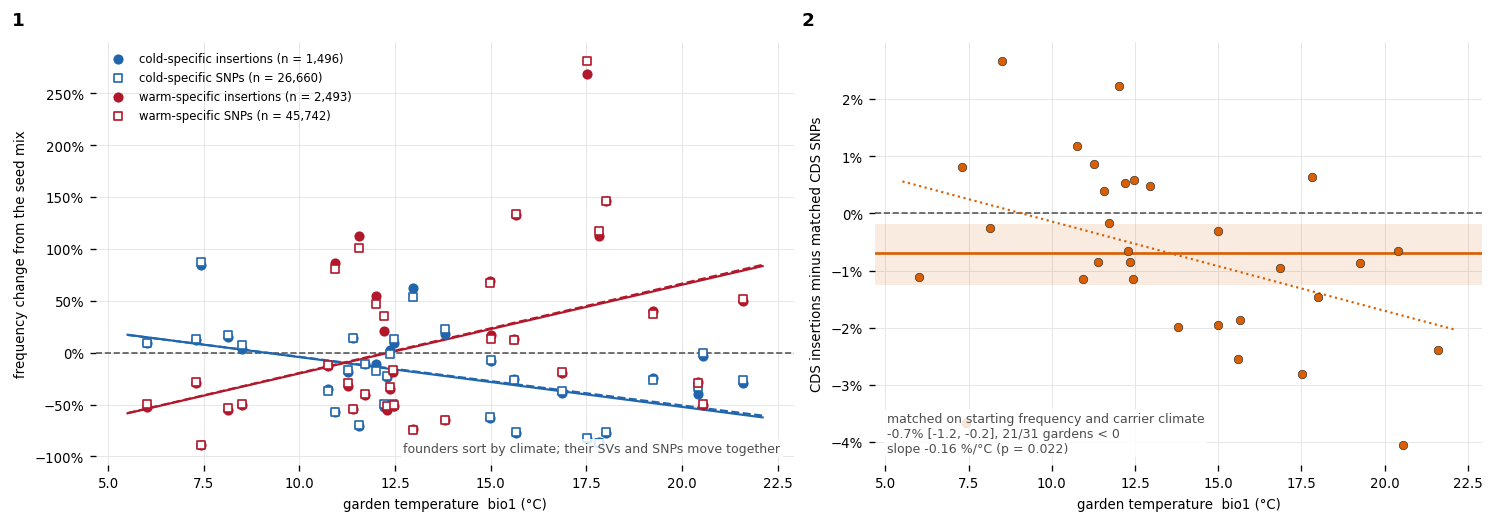

 step                                                    cls  slope_per_C      p    mean      lo      hi
    1                               cold-specific insertions      -0.0480 0.0060 -0.2114     NaN     NaN
    1                                     cold-specific SNPs      -0.0469 0.0072 -0.2042     NaN     NaN
    1                               warm-specific insertions       0.0855 0.0155  0.0998     NaN     NaN
    1                                     warm-specific SNPs       0.0862 0.0152  0.1068     NaN     NaN
    2 CDS insertions vs SNPs, same carrier count and climate      -0.0016 0.0223 -0.0069 -0.0125 -0.0018


In [14]:

xx=np.linspace(BIO.min()-0.5,BIO.max()+0.5,50)
def fitline(a,x,y,col,ls="-"):
    lr=stats.linregress(x,y); a.plot(xx,lr.intercept+lr.slope*xx,color=col,lw=1.3,ls=ls); return lr
fig,ax=plt.subplots(1,2,figsize=(12.5,4.4),gridspec_kw=dict(width_ratios=[1.15,1])); rows=[]
for a in ax: style(a); a.axhline(0,color="0.35",lw=1,ls="--"); a.set_xlabel("garden temperature  bio1 (°C)")
# 1. origin-specific insertions and SNPs, raw change, one panel
a=ax[0]; panel(a,"1")
for o,col in (("cold-specific",OC["cold-specific"]),("warm-specific",OC["warm-specific"])):
    for k,mk,ls,fc in (("ins","o","-",col),("snp","s","--","white")):
        ms=(ORG==o)&(KD==k); d=rel_change(ms); lr=fitline(a,BIO,d,col,ls)
        a.scatter(BIO,d,s=26 if k=="ins" else 22,marker=mk,facecolor=fc,edgecolor=col,linewidth=1.0,zorder=3,label=f"{o} {KL[k]} (n = {int(ms.sum()):,})")
        rows.append(dict(step=1,cls=f"{o} {KL[k]}",slope_per_C=lr.slope,p=lr.pvalue,mean=d.mean()))
a.set_ylabel("frequency change from the seed mix"); a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0)); a.legend(frameon=False,fontsize=7,loc="upper left",ncol=1)
a.annotate("founders sort by climate; their SVs and SNPs move together",xy=(0.98,0.03),xycoords="axes fraction",ha="right",fontsize=7.5,color="0.3",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none",pad=1.5))
# 2. matched on frequency and carrier climate (Figure 2c)
ms=(KD=="ins")&(CX==0); mn=(KD=="snp")&(CX==0)
a=ax[1]; panel(a,"2"); d4=load_diff(ms,mn); m_=d4.mean(); r=np.random.default_rng(2); bs=r.choice(d4,(2000,31)).mean(1); lo,hi=np.percentile(bs,[2.5,97.5])
a.axhspan(lo,hi,color=KC["ins"],alpha=0.12,lw=0); a.axhline(m_,color=KC["ins"],lw=1.6); lr=fitline(a,BIO,d4,KC["ins"],":")
a.scatter(BIO,d4,s=26,color=KC["ins"],edgecolor="0.2",linewidth=0.4,zorder=3); a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
a.set_ylabel("CDS insertions minus matched CDS SNPs")
rows.append(dict(step=2,cls="CDS insertions vs SNPs, same carrier count and climate",slope_per_C=lr.slope,p=lr.pvalue,mean=m_,lo=lo,hi=hi))
a.annotate(f"matched on starting frequency and carrier climate\n{100*m_:+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}], {(d4<0).sum()}/31 gardens < 0\nslope {lr.slope*100:+.2f} %/°C (p = {lr.pvalue:.2g})",xy=(0.02,0.03),xycoords="axes fraction",fontsize=7.5,color="0.3",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none",pad=1.5))
fig.tight_layout(); fig.savefig(f"{G}/plots/fig2_walkthrough.png",dpi=200); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))


### Insertions vs deletions per garden, matched and unmatched (Figure 2 pipeline)

Same data and matching as Figure 2c/d: kMate's per-pool allele frequencies (`garden_af_event.npz`),
SNPs matched on carrier count × carrier-origin-climate quintile **within the same origin class**
(`matched_snps`/`load_diff`, as in panel c). Insertions and deletions side by side; cold-specific /
shared / warm-specific overlaid in the same axes (colour), each with its own OLS line on garden
temperature — **bold label = OLS slope p < 0.05**. All contexts pooled (no CDS restriction, unlike
panel c). **Top row** — unmatched: the raw relative change of the class's summed frequency from the
seed mix, no SNP baseline at all (`rel_change`). **Bottom row** — matched: the same events' change
minus their matched SNP set's change (`load_diff`). Comparing the two rows isolates what the
carrier-climate matching removes, per garden rather than as the single OLS slope in panel (d).

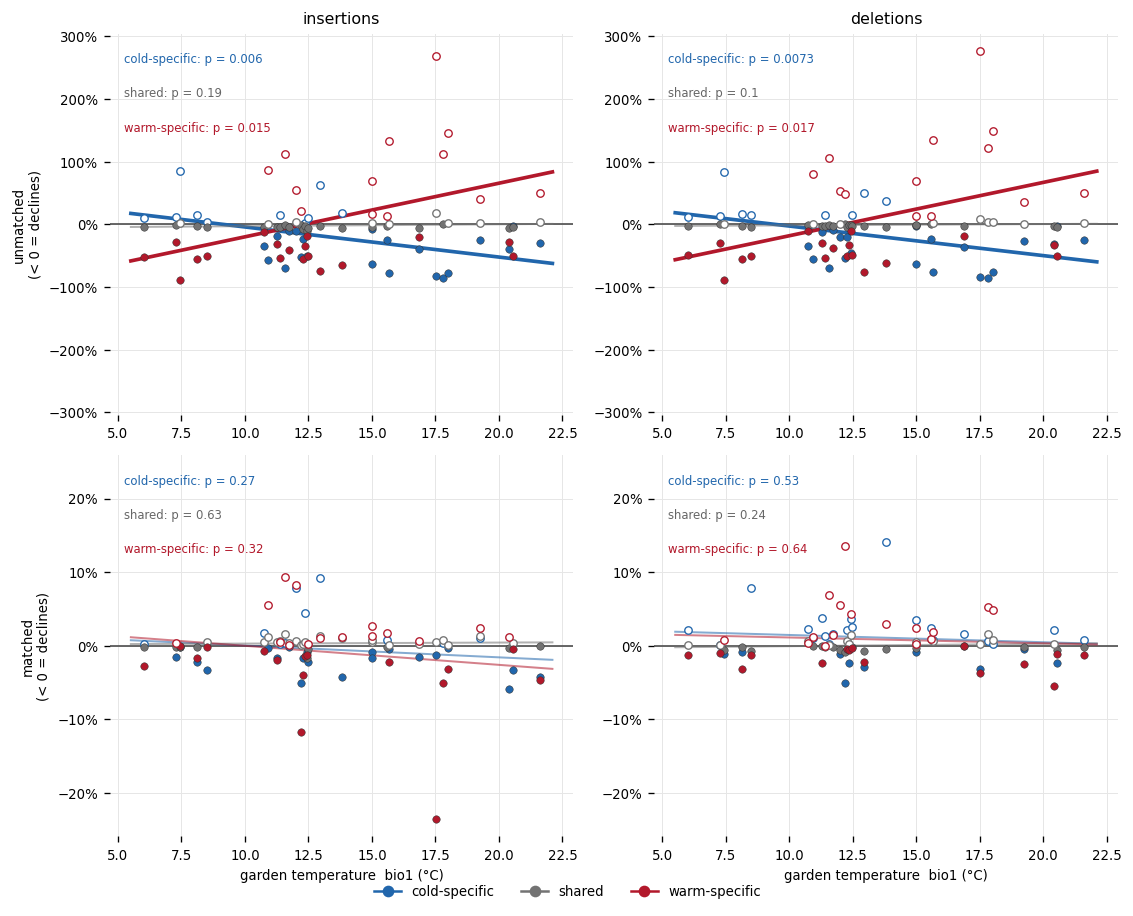

In [15]:

ROWS_ID=[("ins","insertions"),("del","deletions")]
ORIGINS=("cold-specific","shared","warm-specific")
def vals_for(matched):
    v={}
    for k,_ in ROWS_ID:
        for o in ORIGINS:
            ms=(ORG==o)&(KD==k)
            v[(k,o)]=load_diff(ms,(ORG==o)&(KD=="snp")) if matched else rel_change(ms)
    return v
VU,VM=vals_for(False),vals_for(True)
xx=np.linspace(BIO.min()-0.5,BIO.max()+0.5,50)
fig,ax=plt.subplots(2,2,figsize=(9.5,7.5))
for ri,(vals,rlab) in enumerate([(VU,"unmatched"),(VM,"matched")]):
    lim=np.nanmax(np.abs(np.concatenate(list(vals.values()))))*1.1
    for ci,(k,klab) in enumerate(ROWS_ID):
        a=ax[ri,ci]; style(a); a.axhline(0,color="0.3",lw=1.0)
        for oi,o in enumerate(ORIGINS):
            d=vals[(k,o)]; neg=d<0
            a.scatter(BIO[neg],d[neg],s=20,color=OC[o],edgecolor="0.2",linewidth=0.3,zorder=3)
            a.scatter(BIO[~neg],d[~neg],s=20,facecolor="white",edgecolor=OC[o],linewidth=0.8,zorder=3)
            lr=stats.linregress(BIO,d); sig=lr.pvalue<0.05
            a.plot(xx,lr.intercept+lr.slope*xx,color=OC[o],lw=2.2 if sig else 1.2,alpha=1 if sig else 0.55,zorder=2)
            a.annotate(f"{o}: p = {lr.pvalue:.2g}",xy=(0.03,0.95-oi*0.09),xycoords="axes fraction",va="top",
                       fontsize=7,color=OC[o] if o!="shared" else "0.4")
        a.set_ylim(-lim,lim); a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        if ri==0: a.set_title(klab,fontsize=9.5)
        if ri==1: a.set_xlabel("garden temperature  bio1 (°C)")
        if ci==0: a.set_ylabel(f"{rlab}\n(< 0 = declines)")
fig.legend(handles=[plt.Line2D([0],[0],marker="o",color=OC[o],ls="-",label=o) for o in ORIGINS],
           frameon=False,fontsize=8,loc="lower center",ncol=3,bbox_to_anchor=(0.5,-0.015))
fig.tight_layout(); fig.savefig(f"{G}/plots/fig2_by_garden_ins_del.png",dpi=170,bbox_inches="tight"); plt.show()


### Supplementary to Figure 2c — insertions and deletions by genomic context and climate of origin

The same statistic as panel c for every genomic context (rows; each class against SNPs of the same
context) and every origin class of event (one panel each, own x-scale): **all** events, then **shared**
(carried by cold- and warm-origin founders), **cold-specific** (≥ 2 cold-origin carriers, no
warm-origin) and **warm-specific** (the mirror). For each event, its frequency change minus the mean change of its matched SNPs (same context and
origin class, same number of carrier founders, same origin-climate quintile), averaged over the events of
the class and expressed relative to the class's starting frequency; a cold-specific insertion is thus
judged against cold-specific SNPs on the same kind of founder background. Small dots = individual gardens; large points = mean over the gardens of a climate zone
(terciles of garden bio1: cold, mid, hot) ± 95% CI; the printed table gives the all-garden means, gardens below zero and the empirical p
from 1,000 matched SNP sets (two-sided).

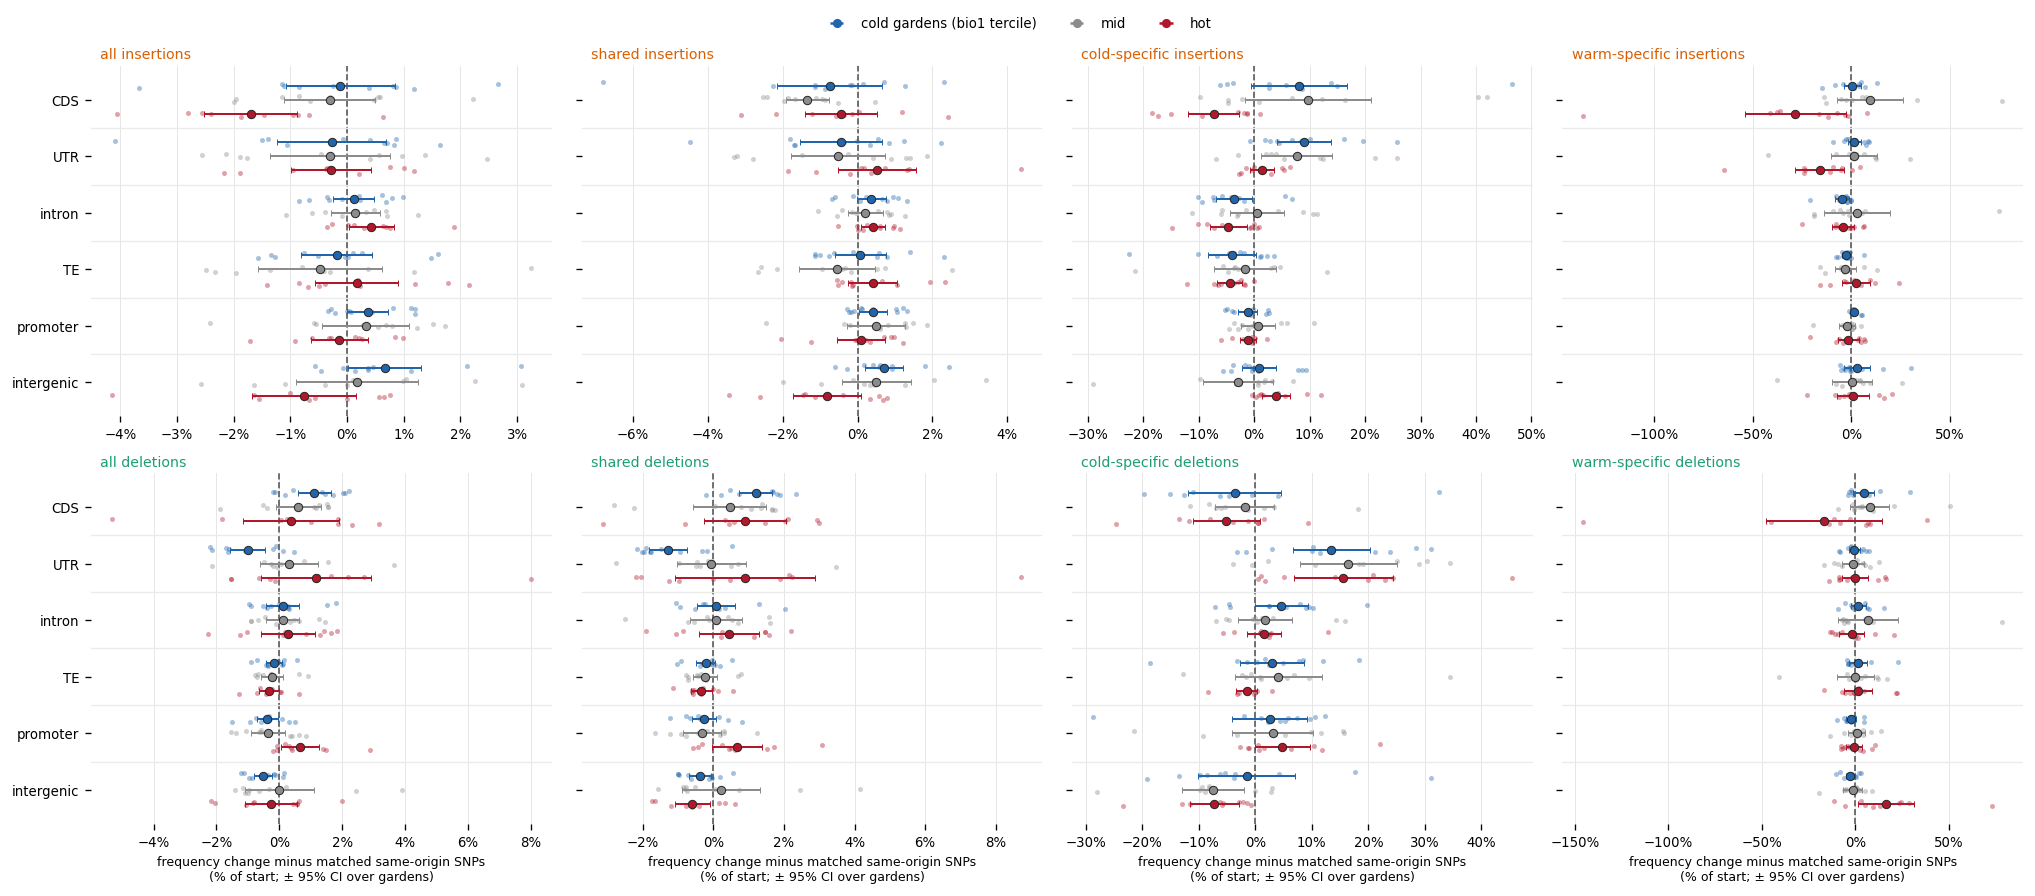

Supplement to 2c  all gardens: mean log load change vs same-origin matched SNPs of the same context, gardens below 0 (of 31), two-sided matched-SNP null p
origin                    all  shared  cold-specific  warm-specific
kind       context                                                 
deletions  CDS         0.0071  0.0087        -0.0357        -0.0140
           TE         -0.0024 -0.0026         0.0187         0.0104
           UTR         0.0012 -0.0018         0.1511        -0.0072
           intergenic -0.0027 -0.0026        -0.0531         0.0377
           intron      0.0016  0.0020         0.0271         0.0201
           promoter   -0.0004  0.0002         0.0344        -0.0095
insertions CDS        -0.0069 -0.0084         0.0363        -0.0590
           TE         -0.0017 -0.0002        -0.0339        -0.0121
           UTR        -0.0029 -0.0015         0.0615        -0.0430
           intergenic  0.0005  0.0015         0.0063         0.0133
           intron      0.0022

In [16]:

ZC={"cold":"#2166AC","mid":"0.55","hot":"#B2182B"}; ZOFF={"cold":-0.25,"mid":0.0,"hot":0.25}
ORIG=(("all",None),("shared","shared"),("cold-specific","cold-specific"),("warm-specific","warm-specific"))
fig,ax=plt.subplots(2,4,figsize=(17,7.2),sharey=True); rows=[]
for r,k in enumerate(("ins","del")):
    for c_,(lab,o) in enumerate(ORIG):
        a=ax[r,c_]; style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--")
        mo=np.ones(KD.size,bool) if o is None else (ORG==o)
        for yi,ctx in enumerate(CTX):
            ms=mo&(KD==k)&(CX==yi); mn=mo&(KD=="snp")&(CX==yi); d=load_diff(ms,mn)
            pe=null_p(d.mean(),matched_null(ms,mn),two_sided=True)
            for z in ("cold","mid","hot"):
                dz=d[ZN==z]; a.scatter(dz,yi+ZOFF[z]+rng.uniform(-0.06,0.06,dz.size),s=9,color=ZC[z],alpha=0.4,linewidth=0,zorder=2)   # one dot per garden
                a.errorbar(dz.mean(),yi+ZOFF[z],xerr=1.96*dz.std(ddof=1)/np.sqrt(dz.size),fmt="o",ms=5,color=ZC[z],mec="0.15",mew=0.6,capsize=2,elinewidth=1.2,zorder=3)
                rows.append(dict(kind=KL[k],origin=lab,context=ctx,zone=z,mean=dz.mean(),gardens_below=int((dz<0).sum()),n_gardens=int(dz.size)))
            rows.append(dict(kind=KL[k],origin=lab,context=ctx,zone="all",mean=d.mean(),gardens_below=int((d<0).sum()),n_gardens=31,n_events=int(ms.sum()),n_snps=int(mn.sum()),null_p_two_sided=pe))
            if yi<5: a.axhline(yi+0.5,color="0.92",lw=0.8)
        a.set_yticks(range(6)); a.set_yticklabels(CTX); a.set_ylim(5.6,-0.6)
        a.annotate(f"{lab} {KL[k]}",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color=KC[k])
        a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        if r==1: a.set_xlabel("frequency change minus matched same-origin SNPs\n(% of start; ± 95% CI over gardens)",fontsize=7.5)
for z,l in (("cold","cold gardens (bio1 tercile)"),("mid","mid"),("hot","hot")): ax[0,0].errorbar([],[],xerr=[],fmt="o",ms=4.5,color=ZC[z],label=l)
fig.legend(frameon=False,fontsize=8,loc="lower center",bbox_to_anchor=(0.5,0.99),ncol=3)
fig.tight_layout(); fig.savefig(f"{G}/plots/supp_fig2c_by_origin.png",dpi=170); plt.show()
T=pd.DataFrame(rows); A=T[T.zone=="all"]
print("Supplement to 2c  all gardens: mean log load change vs same-origin matched SNPs of the same context, gardens below 0 (of 31), two-sided matched-SNP null p")
print(A.pivot_table(index=["kind","context"],columns="origin",values="mean").reindex(columns=[o for o,_ in ORIG]).round(4).to_string())
print(); print(A.pivot_table(index=["kind","context"],columns="origin",values="gardens_below").reindex(columns=[o for o,_ in ORIG]).astype(int).to_string())
print(); print(A.pivot_table(index=["kind","context"],columns="origin",values="null_p_two_sided").reindex(columns=[o for o,_ in ORIG]).round(3).to_string())
print("\nby garden zone (mean):"); print(T[T.zone!="all"].pivot_table(index=["kind","context","origin"],columns="zone",values="mean").reindex(columns=["cold","mid","hot"]).round(4).to_string())


### Summary of the context control — all insertions and deletions, coding vs intron vs intergenic

The same statistic for all insertions and all deletions (any climate of origin) in the three contexts that make the
contrast: coding sequence, introns and intergenic sequence, for each event, its frequency change minus the
mean change of its matched SNPs (same context, same number of carrier founders, same origin-climate
quintile), averaged over the class and expressed relative to the class's starting frequency. Small dots = gardens; large points = zone
mean with a 95% percentile bootstrap CI (2,000 resamples of the zone's gardens).

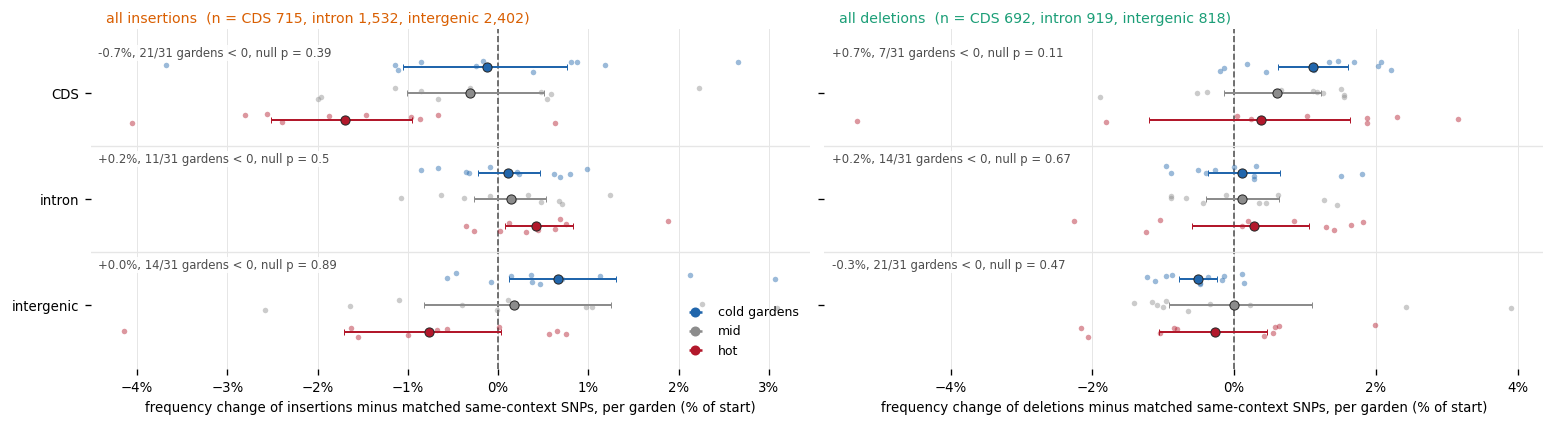

      kind    context  n_events  n_snps    mean  boot_lo  boot_hi  gardens_below  null_p_two_sided
insertions        CDS       715   58560 -0.0069  -0.0125  -0.0018             21             0.385
insertions     intron      1532   55465  0.0022   0.0001   0.0045             11             0.496
insertions intergenic      2402   30992  0.0005  -0.0049   0.0058             14             0.894
 deletions        CDS       692   58560  0.0071   0.0011   0.0120              7             0.107
 deletions     intron       919   55465  0.0016  -0.0022   0.0053             14             0.667
 deletions intergenic       818   30992 -0.0027  -0.0070   0.0020             21             0.471


In [17]:

def bci(v,B=2000,seed=2):
    # percentile bootstrap CI of the mean over gardens (resample gardens with replacement)
    r=np.random.default_rng(seed); bs=r.choice(v,(B,v.size)).mean(1); return np.percentile(bs,2.5),np.percentile(bs,97.5)
SUMC=["CDS","intron","intergenic"]; fig,ax=plt.subplots(1,2,figsize=(13,3.6),sharey=True); rows=[]
for a,k in zip(ax,("ins","del")):
    style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--")
    for yi,ctx in enumerate(SUMC):
        ci=CTX.index(ctx); ms=(KD==k)&(CX==ci); mn=(KD=="snp")&(CX==ci); d=load_diff(ms,mn); pe=null_p(d.mean(),matched_null(ms,mn),two_sided=True)
        for z in ("cold","mid","hot"):
            dz=d[ZN==z]; a.scatter(dz,yi+ZOFF[z]+rng.uniform(-0.06,0.06,dz.size),s=11,color=ZC[z],alpha=0.45,linewidth=0,zorder=2)
            lo,hi=bci(dz); a.errorbar(dz.mean(),yi+ZOFF[z],xerr=[[dz.mean()-lo],[hi-dz.mean()]],fmt="o",ms=5.5,color=ZC[z],mec="0.15",mew=0.6,capsize=2,elinewidth=1.2,zorder=3)
        lo,hi=bci(d); rows.append(dict(kind=KL[k],context=ctx,n_events=int(ms.sum()),n_snps=int(mn.sum()),mean=d.mean(),boot_lo=lo,boot_hi=hi,gardens_below=int((d<0).sum()),null_p_two_sided=pe))
        a.annotate(f"{100*d.mean():+.1f}%, {(d<0).sum()}/31 gardens < 0, null {pfmt(pe)}",xy=(0.01,yi-0.44),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none",pad=1))
        if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
    a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.6,-0.6)
    a.set_xlabel(f"frequency change of {KL[k]} minus matched same-context SNPs, per garden (% of start)",fontsize=8); a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
    a.annotate(f"all {KL[k]}  (n = "+", ".join(f"{c} {int(((KD==k)&(CX==CTX.index(c))).sum()):,}" for c in SUMC)+")",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color=KC[k])
for z,l in (("cold","cold gardens"),("mid","mid"),("hot","hot")): ax[0].errorbar([],[],xerr=[],fmt="o",ms=5,color=ZC[z],label=l)
ax[0].legend(frameon=False,fontsize=7.5,loc="lower right")
fig.tight_layout(); fig.savefig(f"{G}/plots/supp_fig2c_summary.png",dpi=200); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))


## Models and statistics, as run

- **Founder burden (Fig. 2a).** Linear mixed model above, REML by eigendecomposition of **K**
  (EMMA-style one-dimensional search for σ²<sub>g</sub>/σ²<sub>e</sub>), Wald z-tests. `_sv_burden_lmm.py`.
  Joint models add z(SNP CDS rate), z(SNP intergenic rate) [and the indel pair]. Robustness in the
  key-results notebook: permutation of the burden residual (1000×), per-garden fits, rare (2–10 carrier)
  events alone, shifted-annotation null (200 circular shifts, size-matched).
- **Allele frequencies in GrENE-Net (Fig. 2c–d, 3a–b).** kMate's stored per-pool allele frequencies
  (`common/results/pool_matrices/pool_gen9_*`: every plot at its last sampled generation, 352 pools) and
  the seed-mix founding frequency (mean of 8 runs, `af_store/p0_*`). Garden frequency = mean over the
  garden's plots. SV event = sum of its alleles' frequencies, capped at 1. SNPs a random 10% of records,
  short indels a random 10%; filters and labels as in the founder panel (`_sv_garden_af.py`).
- **Matched frequency change (Fig. 2c, 3a–b, supplements).** For each event *v* and garden *s*:
  Δ<sub>v</sub> = *p*<sub>v</sub>(garden) − *p*<sub>v</sub>(seed mix), minus the mean Δ of its matched SNPs
  — all SNPs of the same context (and origin class where stated) with the same carrier count and the
  same carrier-climate quintile (events whose exact cell holds no SNP use their carrier-count bin; none in
  CDS). The differences are averaged over the class and divided by the class's mean starting frequency,
  so the value is a percent of where the class began. Equivalently, the relative change of the summed
  class frequency minus that of the composition-matched SNP set. **Test:** 95% percentile bootstrap over
  the 31 gardens (2,000 resamples); the stricter matched-SNP null (1,000 random sets, one SNP per event
  from its matches, same statistic) is printed in the tables. Gardens share one founder pool, so garden
  counts ("21/31") are descriptive.
- **Origin × garden (Fig. 2d).** Origin labels from each variant's own carriers: cold-specific = ≥ 2
  cold-origin and 0 warm-origin carriers (origin tertiles of founder bio1: ≤ 8.26 °C cold, ≥ 10.72 °C
  warm), warm-specific the mirror. Per class and kind, log[*L*<sub>garden</sub>/*L*<sub>0</sub>] per
  garden, OLS on garden bio1 over 31 gardens.
- **Robustness (`_sv_main_figures_checks.py`).** Burden model with founder origin bio1 (and bio1²) as
  extra covariates: β₁ unchanged (−0.22); the burden–fitness relation holds within origin tertiles
  (cold ρ = −0.51, warm ρ = −0.27). Spectra without singletons (minor-allele count ≥ 2): same ordering
  (values printed under Figure 1).